<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# Procesamiento de lenguaje natural
## Custom embedddings con Gensim



### Objetivo
El objetivo es utilizar documentos / corpus para crear embeddings de palabras basado en ese contexto. Se utilizará canciones de bandas para generar los embeddings, es decir, que los vectores tendrán la forma en función de como esa banda haya utilizado las palabras en sus canciones.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import multiprocessing
try:
  from gensim.models import Word2Vec
except:
  !pip install gensim
  from gensim.models import Word2Vec

### Datos
Utilizaremos como dataset canciones de bandas de habla inglesa.

In [2]:
# Descargar la carpeta de dataset
# Cambio respecto de la plantilla: `!wget` y `!unzip` se reemplazan por urllib y zipfile, de la biblioteca
# estándar, para que la celda corra igual en Colab, Linux, Windows y macOS (que no trae wget).
import os
import urllib.request
import zipfile
if os.access('./songs_dataset', os.F_OK) is False:
    if os.access('songs_dataset.zip', os.F_OK) is False:
        urllib.request.urlretrieve('https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/raw/main/datasets/songs_dataset.zip', 'songs_dataset.zip')
    with zipfile.ZipFile('songs_dataset.zip') as z:
        z.extractall('.')
else:
    print("El dataset ya se encuentra descargado")

In [3]:
# Posibles bandas
os.listdir("./songs_dataset/")

['prince.txt',
 'dickinson.txt',
 'notorious-big.txt',
 'beatles.txt',
 'bob-dylan.txt',
 'bjork.txt',
 'johnny-cash.txt',
 'disney.txt',
 'janisjoplin.txt',
 'kanye.txt',
 'bob-marley.txt',
 'leonard-cohen.txt',
 'ludacris.txt',
 'adele.txt',
 'alicia-keys.txt',
 'joni-mitchell.txt',
 'amy-winehouse.txt',
 'lorde.txt',
 'rihanna.txt',
 'Kanye_West.txt',
 'nirvana.txt',
 'cake.txt',
 'bieber.txt',
 'notorious_big.txt',
 'missy-elliott.txt',
 'dolly-parton.txt',
 'jimi-hendrix.txt',
 'michael-jackson.txt',
 'al-green.txt',
 'lil-wayne.txt',
 'lady-gaga.txt',
 'lin-manuel-miranda.txt',
 'nursery_rhymes.txt',
 'dj-khaled.txt',
 'radiohead.txt',
 'patti-smith.txt',
 'blink-182.txt',
 'Lil_Wayne.txt',
 'dr-seuss.txt',
 'r-kelly.txt',
 'drake.txt',
 'britney-spears.txt',
 'bruce-springsteen.txt',
 'nicki-minaj.txt',
 'kanye-west.txt',
 'paul-simon.txt',
 'nickelback.txt',
 'eminem.txt',
 'bruno-mars.txt']

In [4]:
# Armar el dataset utilizando salto de línea para separar las oraciones/docs
df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)
df.head()

/var/folders/0z/c4q8w4sj115gdwrpjh5wn8400000gn/T/ipykernel_23236/3849064916.py:2: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support separators > 1 char, including regex separators; you can avoid this warning by specifying engine='python'.
  df = pd.read_csv('songs_dataset/beatles.txt', sep='/n', header=None)


,0
0,"Yesterday, all my troubles seemed so far away"
1,Now it looks as though they're here to stay
2,"Oh, I believe in yesterday Suddenly, I'm not h..."
3,There's a shadow hanging over me.
4,"Oh, yesterday came suddenly Why she had to go ..."


In [5]:
print("Cantidad de documentos:", df.shape[0])

Cantidad de documentos: 1846


### 1 - Preprocesamiento

In [6]:
from tensorflow.keras.preprocessing.text import text_to_word_sequence

sentence_tokens = []
# Recorrer todas las filas y transformar las oraciones
# en una secuencia de palabras (esto podría realizarse con NLTK o spaCy también)
for _, row in df[:None].iterrows():
    sentence_tokens.append(text_to_word_sequence(row[0]))

In [7]:
# Demos un vistazo
sentence_tokens[:2]

[['yesterday', 'all', 'my', 'troubles', 'seemed', 'so', 'far', 'away'],
 ['now', 'it', 'looks', 'as', 'though', "they're", 'here', 'to', 'stay']]

### 2 - Crear los vectores (word2vec)

In [8]:
from gensim.models.callbacks import CallbackAny2Vec
# Durante el entrenamiento gensim por defecto no informa el "loss" en cada época
# Sobrecargamos el callback para poder tener esta información
class callback(CallbackAny2Vec):
    """
    Callback to print loss after each epoch
    """
    def __init__(self):
        self.epoch = 0

    def on_epoch_end(self, model):
        loss = model.get_latest_training_loss()
        if self.epoch == 0:
            print('Loss after epoch {}: {}'.format(self.epoch, loss))
        else:
            print('Loss after epoch {}: {}'.format(self.epoch, loss- self.loss_previous_step))
        self.epoch += 1
        self.loss_previous_step = loss

In [9]:
# Crearmos el modelo generador de vectores
# En este caso utilizaremos la estructura modelo Skipgram
w2v_model = Word2Vec(min_count=5,    # frecuencia mínima de palabra para incluirla en el vocabulario
                     window=2,       # cant de palabras antes y desp de la predicha
                     vector_size=300,       # dimensionalidad de los vectores
                     negative=20,    # cantidad de negative samples... 0 es no se usa
                     workers=1,      # si tienen más cores pueden cambiar este valor
                     sg=1)           # modelo 0:CBOW  1:skipgram

In [10]:
# Obtener el vocabulario con los tokens
w2v_model.build_vocab(sentence_tokens)

In [11]:
# Cantidad de filas/docs encontradas en el corpus
print("Cantidad de docs en el corpus:", w2v_model.corpus_count)

Cantidad de docs en el corpus: 1846


In [12]:
# Cantidad de words encontradas en el corpus
print("Cantidad de words distintas en el corpus:", len(w2v_model.wv.index_to_key))

Cantidad de words distintas en el corpus: 445


### 3 - Entrenar embeddings

In [13]:
# Entrenamos el modelo generador de vectores
# Utilizamos nuestro callback
w2v_model.train(sentence_tokens,
                 total_examples=w2v_model.corpus_count,
                 epochs=20,
                 compute_loss = True,
                 callbacks=[callback()]
                 )

Loss after epoch 0: 113045.2421875
Loss after epoch 1: 65966.5703125
Loss after epoch 2: 65935.015625
Loss after epoch 3: 65718.296875


Loss after epoch 4: 63874.96875
Loss after epoch 5: 64160.875


Loss after epoch 6: 64080.5
Loss after epoch 7: 64815.09375
Loss after epoch 8: 62632.75


Loss after epoch 9: 60452.75
Loss after epoch 10: 59839.6875


Loss after epoch 11: 58884.25
Loss after epoch 12: 57715.9375
Loss after epoch 13: 56494.1875


Loss after epoch 14: 55817.25
Loss after epoch 15: 55843.0625
Loss after epoch 16: 51722.6875


Loss after epoch 17: 49857.875
Loss after epoch 18: 49592.125
Loss after epoch 19: 48960.0


(156986, 287740)

### 4 - Ensayar

In [14]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["darling"], topn=10)

[('pretty', 0.8954243063926697),
 ('sleep', 0.8665637969970703),
 ('help', 0.8439376950263977),
 ('cry', 0.83512943983078),
 ('not', 0.8309614658355713),
 ('try', 0.8276940584182739),
 ('peace', 0.8144854307174683),
 ('little', 0.8140544295310974),
 ('twist', 0.8123906850814819),
 ('seems', 0.8079560995101929)]

In [15]:
# Palabras que MENOS se relacionan con...:
w2v_model.wv.most_similar(negative=["love"], topn=10)

[('shake', -0.2287278026342392),
 ('four', -0.23302021622657776),
 ('five', -0.237460196018219),
 ('six', -0.2378387749195099),
 ('bang', -0.2483242005109787),
 ('our', -0.25538891553878784),
 ('day', -0.2689763307571411),
 ('going', -0.2692073881626129),
 ('here', -0.26990994811058044),
 ('three', -0.28389739990234375)]

In [16]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["four"], topn=10)

[('five', 0.9813730716705322),
 ('three', 0.9745771884918213),
 ('six', 0.9710819721221924),
 ('seven', 0.9584385752677917),
 ('two', 0.9517235159873962),
 ('sixty', 0.8990404605865479),
 ('one', 0.7951188683509827),
 ('crying', 0.7946323752403259),
 ('us', 0.774010956287384),
 ("i'm", 0.7508406639099121)]

In [17]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["money"], topn=5)

[("can't", 0.9434012770652771),
 ('buy', 0.9396973252296448),
 ('much', 0.9033190011978149),
 ('just', 0.8509107828140259),
 ('hide', 0.8355358839035034)]

In [18]:
# Ensayar con una palabra que no está en el vocabulario:
# Word2Vec no tiene vector para una palabra que no vio y tira KeyError. Lo atrapo y lo muestro,
# para que el notebook corra de punta a punta.
try:
    w2v_model.wv.most_similar(negative=["diedaa"])
except KeyError as error:
    print("KeyError:", error)

KeyError: "Key 'diedaa' not present in vocabulary"


In [19]:
# el método `get_vector` permite obtener los vectores:
vector_love = w2v_model.wv.get_vector("love")
print(vector_love)

[ 0.06138294  0.05881053 -0.06370477  0.02445546 -0.20152311 -0.18612298
 -0.15284492  0.4548641  -0.042179    0.03535716  0.13657664 -0.1851985
 -0.18126567  0.22149132 -0.3038017  -0.23970504  0.0709474  -0.05679084
 -0.05165781 -0.23843321 -0.08529595  0.19564523 -0.07678778  0.03796823
  0.07516409 -0.04826145  0.07379413  0.10396487  0.00737745 -0.22765112
 -0.04566921  0.1293697   0.27785546  0.19387001 -0.13509622  0.20857269
  0.4091703  -0.00386562 -0.10631571 -0.09057102  0.02400816 -0.08005267
  0.13399461  0.08833719 -0.01894974  0.08592648 -0.15905555  0.10259393
  0.1445954  -0.1209247  -0.279195   -0.04061342  0.11381969  0.31366253
 -0.07408687  0.1397688   0.22791368  0.1320968  -0.01811604  0.09772383
  0.09249984 -0.14871608 -0.16348287 -0.13202605 -0.0983391   0.02714311
  0.16531329  0.2605218  -0.03259389 -0.02894598  0.11621305 -0.06974123
  0.09562718 -0.1527624   0.22071022  0.15996738  0.15890466 -0.04710886
 -0.12556134 -0.03993148 -0.10795182  0.01878742  0.

In [20]:
# el método `most_similar` también permite comparar a partir de vectores
w2v_model.wv.most_similar(vector_love)

[('love', 1.0000001192092896),
 ('babe', 0.9085147380828857),
 ('someone', 0.8886134624481201),
 ('need', 0.8827983140945435),
 ('nothing', 0.8740261793136597),
 ("didn't", 0.8638365268707275),
 ("there's", 0.8526695370674133),
 ('you', 0.8456733226776123),
 ('feed', 0.844502866268158),
 ('somebody', 0.8362798094749451)]

In [21]:
# Palabras que MÁS se relacionan con...:
w2v_model.wv.most_similar(positive=["love"], topn=10)

[('babe', 0.9085147380828857),
 ('someone', 0.8886134028434753),
 ('need', 0.8827983140945435),
 ('nothing', 0.8740261793136597),
 ("didn't", 0.8638365268707275),
 ("there's", 0.8526695370674133),
 ('you', 0.8456733226776123),
 ('feed', 0.844502866268158),
 ('somebody', 0.8362798094749451),
 ('buy', 0.8351726531982422)]

### 5 - Visualizar agrupación de vectores

In [22]:
from sklearn.decomposition import IncrementalPCA
from sklearn.manifold import TSNE
import numpy as np

def reduce_dimensions(model, num_dimensions = 2 ):

    vectors = np.asarray(model.wv.vectors)
    labels = np.asarray(model.wv.index_to_key)

    tsne = TSNE(n_components=num_dimensions, random_state=0)
    vectors = tsne.fit_transform(vectors)

    return vectors, labels

In [23]:
# Graficar los embedddings en 2D
import plotly.graph_objects as go
import plotly.express as px

vecs, labels = reduce_dimensions(w2v_model)

MAX_WORDS=200
fig = px.scatter(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], text=labels[:MAX_WORDS])
fig.show(renderer="colab") # esto para plotly en colab

In [24]:
# Graficar los embedddings en 3D

vecs, labels = reduce_dimensions(w2v_model,3)

fig = px.scatter_3d(x=vecs[:MAX_WORDS,0], y=vecs[:MAX_WORDS,1], z=vecs[:MAX_WORDS,2],text=labels[:MAX_WORDS])
fig.update_traces(marker_size = 2)
fig.show(renderer="colab") # esto para plotly en colab

In [25]:
# También se pueden guardar los vectores y labels como tsv para graficar en
# http://projector.tensorflow.org/


vectors = np.asarray(w2v_model.wv.vectors)
labels = list(w2v_model.wv.index_to_key)

np.savetxt("vectors.tsv", vectors, delimiter="\t")

with open("labels.tsv", "w") as fp:
    for item in labels:
        fp.write("%s\n" % item)

### Consigna del desafío 2

**Cada experimento realizado debe estar acompañado de una explicación o interpretación de lo observado, incluido el sustento de las decisiones que tomaron (como modificación de hiperparámetros)**

Recuerden que su notebook de entrega debe poder correrse de inicio a fin sin la aparición de errores.

- Crear sus propios vectores con Gensim basado en lo visto en clase con un corpus propio (revisar enlaces sugeridos en clase 2 sobre opciones de dataset)
- Elegir términos de interés y buscar términos más similares y menos similares.
- Realizar una reduccion de dimensionalidad a los embeddings, llevándolos a 2 dimensiones. Graficar los embeddings proyectados y seleccionar una cantidad de términos (variable MAX_WORDS) de forma tal que la visualización sea adecuada.
- Inspeccionar el grafico y buscar pequeños grupos de palabras que puedan formarse. Interpretarlos e intentar obtener conclusiones. En lo posible, acompañar los grupos de palabras con capturas (y pegarlas en celdas de texto)

---
# Resolución

**Corpus:** *Don Quijote de la Mancha*, de Miguel de Cervantes, en español y con sus dos partes (1605 y 1615): el libro [#2000 de Project Gutenberg](https://www.gutenberg.org/ebooks/2000). Lo elegí porque:
- **Es largo:** unas 384.000 palabras, 27 veces el corpus de los Beatles. Con un corpus chico el modelo se sobreajusta a frases puntuales, como pasó con *yellow submarine*.
- **Tiene personajes, lugares, objetos y temas muy marcados** (la caballería, Dulcinea, el gobierno de la ínsula), así que se puede juzgar si los vecinos de una palabra tienen sentido.
- **Está en el español de principios del siglo XVII**, con formas antiguas (*mesmo*, *agora*, *fermosa*) que conviven con las modernas (*mismo*, *ahora*, *hermosa*). Permite ver si el modelo descubre solo que son la misma palabra.
- Es de dominio público, y el desafío 3 usa el mismo corpus.

**Plan:** 1. corpus y preprocesamiento · 2. modelo base · 3. experimentos con los hiperparámetros · 4. términos de interés · 5. analogías · 6. t-SNE y clusters · 7. conclusiones.

De la plantilla reutilizo `text_to_word_sequence`, la clase `callback` (la loss de cada época) y la función `reduce_dimensions` (t-SNE).

In [26]:
import contextlib
import io
import os
import re
import socket
import sys
import time
import urllib.request
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import nltk
except ImportError:
    %pip install nltk
    import nltk
from nltk.corpus import stopwords

nltk.download(['punkt_tab', 'stopwords'], quiet=True)  # segmentador de oraciones y stopwords en español
pd.set_option('display.max_colwidth', None)            # mostrar completas las listas de vecinos

## 1. Corpus y preprocesamiento

### 1.1 Descarga

Pruebo una lista de URLs en orden: primero el sitio de Project Gutenberg y después dos espejos oficiales, por si el sitio principal no responde (desde mi máquina devolvía error 503). Si el archivo ya está, no se vuelve a bajar. Los espejos son lentos, así que la descarga se da por buena solo si el archivo llega hasta la marca de fin del libro: una descarga cortada pasaría desapercibida.

In [27]:
URLS_QUIJOTE = [
    'https://www.gutenberg.org/cache/epub/2000/pg2000.txt',  # sitio principal de Project Gutenberg
    'https://aleph.pglaf.org/2/0/0/2000/2000-0.txt',         # espejos
    'https://gutenberg.pglaf.org/2/0/0/2000/2000-0.txt',
]
ARCHIVO_QUIJOTE = 'quijote.txt'
socket.setdefaulttimeout(60)  # que un servidor que no contesta no frene el notebook

if os.path.exists(ARCHIVO_QUIJOTE):
    print('El corpus ya se encuentra descargado')
else:
    for url in URLS_QUIJOTE:
        try:
            urllib.request.urlretrieve(url, ARCHIVO_QUIJOTE + '.parcial')
            with open(ARCHIVO_QUIJOTE + '.parcial', encoding='utf-8') as f:
                if '*** END OF' not in f.read():
                    raise ValueError('la descarga quedó cortada')
            os.replace(ARCHIVO_QUIJOTE + '.parcial', ARCHIVO_QUIJOTE)
            print('Descargado de', url)
            break
        except Exception as e:
            print(f'No se pudo descargar de {url}: {e}')
    else:
        raise RuntimeError('No se pudo descargar el corpus de ninguna URL')

with open(ARCHIVO_QUIJOTE, encoding='utf-8') as f:
    texto = f.read()
print(f'{len(texto):,} caracteres')

No se pudo descargar de https://www.gutenberg.org/cache/epub/2000/pg2000.txt: HTTP Error 503: Service Unavailable


Descargado de https://aleph.pglaf.org/2/0/0/2000/2000-0.txt
2,110,809 caracteres


### 1.2 Limpieza: encabezado y pie de Project Gutenberg

Los libros de Gutenberg traen, antes y después del texto, un encabezado y una licencia en inglés. Me quedo con lo que está entre las marcas `*** START OF THE PROJECT GUTENBERG EBOOK … ***` y `*** END OF THE PROJECT GUTENBERG EBOOK … ***` (en libros más viejos dice *THIS* en vez de *THE*). Si no, palabras como *project*, *gutenberg* o *license* entrarían al vocabulario. El archivo de los espejos trae solo las marcas; el del sitio principal trae además la licencia, y la misma expresión regular sirve para los dos.

In [28]:
inicio = re.search(r'\*\*\* ?START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*', texto)
fin = re.search(r'\*\*\* ?END OF (THE|THIS) PROJECT GUTENBERG EBOOK', texto)
libro = texto[inicio.end():fin.start()].strip()
print(f'Se descartan {inicio.end():,} caracteres al principio y {len(texto) - fin.start():,} al final. Quedan {len(libro):,}.\n')
print('Empieza:', ' '.join(libro[:300].split()), '[...]\n')
print('Termina: [...]', ' '.join(libro[-230:].split()))

Se descartan 49 caracteres al principio y 48 al final. Quedan 2,110,704.

Empieza: El ingenioso hidalgo don Quijote de la Mancha por Miguel de Cervantes Saavedra El ingenioso hidalgo don Quijote de la Mancha Tasa Testimonio de las erratas El Rey Al Duque de Béjar Prólogo Al libro de don Quijote de la Mancha Que trata de la condición y ejercicio del famoso h [...]

Termina: [...] deseo que poner en aborrecimiento de los hombres las fingidas y disparatadas historias de los libros de caballerías, que, por las de mi verdadero don Quijote, van ya tropezando, y han de caer del todo, sin duda alguna. Vale. Fin


### 1.3 Segmentación en oraciones

La plantilla toma cada línea como un documento porque en las canciones cada línea es una oración. En un libro de Gutenberg las líneas se cortan a unos 70 caracteres, en cualquier lugar de la oración, así que hay que **unir las líneas y segmentar en oraciones completas**:
1. **Párrafos:** Gutenberg separa los párrafos con una línea en blanco. Dentro de cada párrafo, las líneas se unen con un espacio. Cortar primero en párrafos evita que los títulos del índice o los versos de los poemas, que no terminan en punto, queden pegados en una sola "oración" gigante.
2. **Oraciones:** cada párrafo se corta con `nltk.sent_tokenize(párrafo, language='spanish')`, el segmentador *punkt* de NLTK entrenado para español.

In [29]:
parrafos = [' '.join(p.split()) for p in re.split(r'\n\s*\n', libro) if p.strip()]
oraciones = [o for p in parrafos for o in nltk.sent_tokenize(p, language='spanish')]
print(f'{len(parrafos):,} párrafos → {len(oraciones):,} oraciones\n')
for o in oraciones[2000:2005]:
    print('·', o)

5,334 párrafos → 10,986 oraciones

· — Y yo lo entiendo así —respondió don Quijote.
· El cual, pasando al tercero, preguntó lo que a los otros; el cual, de presto y con mucho desenfado, respondió y dijo:
· — Yo voy por cinco años a las señoras gurapas por faltarme diez ducados.
· — Yo daré veinte de muy buena gana —dijo don Quijote— por libraros desa pesadumbre.
· — Eso me parece —respondió el galeote— como quien tiene dineros en mitad del golfo y se está muriendo de hambre, sin tener adonde comprar lo que ha menester.


### 1.4 Tokenización

Uso `text_to_word_sequence`, como la plantilla: pasa a minúsculas, saca los signos de su lista de filtros y separa por espacios. Pero sus filtros por defecto son los signos del inglés, y **dejan pegados a las palabras** los del español y los de esta edición:
- `¿` y `¡`, que abren las preguntas y las exclamaciones;
- `«` y `»`, las comillas, y `…`;
- `—`, la raya de los diálogos (`—dijo don Quijote—`);
- `'`, que esta edición usa como comilla interna (`''¡Qué don Álvaro de Lu-,''`).

Si no se filtran, "¿qué" y "qué" quedan como dos palabras distintas. Los agrego a los filtros:

In [30]:
FILTROS_KERAS = '!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n'  # los de text_to_word_sequence por defecto
FILTROS = FILTROS_KERAS + "¿¡«»—…'"

ejemplo = next(o for o in oraciones if o.startswith('— ¿') and '—' in o[3:] and len(o) < 90)
print(ejemplo, '\n')
print('Filtros por defecto:', text_to_word_sequence(ejemplo))
print('Filtros ampliados:  ', text_to_word_sequence(ejemplo, filters=FILTROS))

— ¿De modo —dijo don Quijote— que ya la historia es acabada? 

Filtros por defecto: ['—', '¿de', 'modo', '—dijo', 'don', 'quijote—', 'que', 'ya', 'la', 'historia', 'es', 'acabada']
Filtros ampliados:   ['de', 'modo', 'dijo', 'don', 'quijote', 'que', 'ya', 'la', 'historia', 'es', 'acabada']


In [31]:
oraciones_tokens = [t for t in (text_to_word_sequence(o, filters=FILTROS) for o in oraciones) if t]
frecuencias = Counter(w for t in oraciones_tokens for w in t)
largos = np.array([len(t) for t in oraciones_tokens])
largos_beatles = np.array([len(t) for t in sentence_tokens])  # el corpus de la plantilla

pd.DataFrame({
    'documentos': [len(sentence_tokens), len(oraciones_tokens)],
    'tokens': [largos_beatles.sum(), largos.sum()],
    'tokens por documento (mediana)': [np.median(largos_beatles), np.median(largos)],
    'palabras distintas': [len({w for t in sentence_tokens for w in t}), len(frecuencias)],
    'palabras con 5 apariciones o más': [len(w2v_model.wv), sum(c >= 5 for c in frecuencias.values())],
}, index=['Beatles (plantilla)', 'Don Quijote'])

,documentos,tokens,tokens por documento (mediana),palabras distintas,palabras con 5 apariciones o más
Beatles (plantilla),1846,14387,7.0,1628,445
Don Quijote,10986,383640,28.0,22950,5321


In [32]:
hapax = sum(c == 1 for c in frecuencias.values())
print(f'Palabras que aparecen una sola vez: {hapax:,} ({hapax / len(frecuencias):.0%} del vocabulario)')
print(f'Largo de las oraciones en tokens: mediana {np.median(largos):.0f} · percentil 90 {np.percentile(largos, 90):.0f} · máximo {largos.max()}')
print(f'La más larga empieza así: «{max(oraciones, key=len)[:110]}…»')
for k in (2, 5, 10):
    tokens_k = sum(c for c in frecuencias.values() if c >= k)
    print(f'Con min_count={k:<2}: {sum(c >= k for c in frecuencias.values()):>6,} palabras, que cubren el {tokens_k / largos.sum():.1%} de los tokens')
print('\nLas 25 más frecuentes:', ', '.join(f'{w} ({c:,})' for w, c in frecuencias.most_common(25)))

Palabras que aparecen una sola vez: 11,158 (49% del vocabulario)
Largo de las oraciones en tokens: mediana 28 · percentil 90 73 · máximo 503
La más larga empieza así: «Por la cual vos damos licencia y facultad para que, por tiempo y espacio de diez años, cumplidos primeros sigu…»
Con min_count=2 : 11,792 palabras, que cubren el 97.1% de los tokens
Con min_count=5 :  5,321 palabras, que cubren el 92.7% de los tokens
Con min_count=10:  3,020 palabras, que cubren el 88.8% de los tokens

Las 25 más frecuentes: que (20,769), de (18,410), y (18,272), la (10,492), a (9,876), en (8,285), el (8,265), no (6,346), los (4,769), se (4,752), con (4,275), por (3,945), lo (3,492), las (3,486), le (3,420), su (3,388), don (2,714), del (2,536), me (2,345), como (2,270), quijote (2,241), sancho (2,174), es (2,145), yo (2,077), más (2,055)


**Análisis**

- **Documentos:** 10.986 oraciones, contra 1.846 líneas de los Beatles, y 27 veces más tokens. Las oraciones de Cervantes son largas: 28 tokens de mediana y 73 en el percentil 90, contra 7 de una línea de canción. La más larga, de 503 tokens, es el privilegio del rey del comienzo del libro, un texto legal sin un solo punto. **Con oraciones así, la ventana de 2 de la plantilla toma muy poco contexto** (lo pruebo en §3.2).
- **Ley de Zipf:** de 22.950 palabras distintas, casi la mitad aparece una sola vez. Con `min_count=5` el vocabulario baja a 5.321 palabras, menos de la cuarta parte, que igual cubren el 92.7 % de los tokens: las palabras que quedan afuera son muchas, pero aparecen poco. Con `min_count=2` ya se descarta la mitad del vocabulario (§3.4).
- **Las más frecuentes son stopwords** (*que*, *de*, *y*, *la*), seguidas de los protagonistas: *don*, *quijote* y *sancho*. **No las saco del corpus:** son el contexto de las demás palabras, y sacarlas juntaría en la ventana palabras que en la oración estaban lejos. Además Gensim ya descarta al azar parte de sus apariciones (parámetro `sample`). Sí las saco para graficar (§6).

## 2. Modelo base

| Hiperparámetro | Valor | Por qué |
|---|---|---|
| `sg` | 1 (skip-gram) | Para Word2Vec el corpus es chico. Skip-gram arma un par [target, contexto] por cada palabra de la ventana, así que le saca más ejemplos a cada oración, y aprende mejor las palabras poco frecuentes. Lo comparo con CBOW en §3.1. |
| `window` | 5 | Las oraciones tienen 28 tokens de mediana: con la ventana de 2 de la plantilla, cada palabra ve una parte muy chica de su oración. 5 es el valor por defecto de Gensim. |
| `vector_size` | 100 | Con unas 384.000 palabras no hay información para llenar 300 dimensiones: como se dijo en clase, subirlo tiene sentido con un corpus grande. |
| `min_count` | 5 | Como en la plantilla. Una palabra que aparece menos de 5 veces tiene muy pocos contextos para ubicar su vector. Quedan 5.321 palabras. |
| `negative` | 10 | Con un corpus chico conviene muestrear más negativos. Mikolov et al. (2013) recomiendan entre 5 y 20 en corpus chicos: tomo un valor intermedio. |
| `epochs` | 20 | Como en la plantilla. El valor por defecto de Gensim, 5, es poco para un corpus chico. |
| `seed`, `workers` | 42, 1 | Con un solo hilo y la semilla fija, cada corrida da exactamente los mismos vectores: Gensim 4 inicializa la matriz con un generador de NumPy con esa semilla. Con más hilos, el orden en que se actualizan los vectores cambia de una corrida a otra, y los vectores también. |

El resto queda en los valores por defecto de Gensim. Entre ellos, `sample=0.001`, que descarta al azar parte de las apariciones de las palabras muy frecuentes (*que*, *de*, *y*) para que no dominen el entrenamiento, y la tasa de aprendizaje, que baja linealmente de 0.025 a 0.0001 a lo largo de las épocas.

`entrenar()` arma el modelo con estos valores y permite cambiar alguno para los experimentos. Además filtra un aviso de Gensim: la versión 4.4 está compilada con Cython 3, que confunde con un error el caso en que un producto punto da exactamente −1. Escribe `Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'` y usa 0 en esa única cuenta, sin cortar el entrenamiento. Pasa unas pocas veces entre cientos de millones de productos y no cambia los resultados, pero en la salida parece un error. `entrenar()` descarta solo esa línea y deja pasar cualquier otro aviso.

In [33]:
BASE = dict(sg=1, window=5, vector_size=100, min_count=5, negative=10, epochs=20, seed=42, workers=1)


def entrenar(**cambios):
    """Entrena un Word2Vec con las oraciones del Quijote y BASE, cambiando solo los parámetros indicados."""
    avisos = io.StringIO()
    inicio = time.time()
    with contextlib.redirect_stderr(avisos):
        m = Word2Vec(oraciones_tokens, **{**BASE, **cambios})
    m.segundos = time.time() - inicio
    otros = [linea for linea in avisos.getvalue().splitlines() if 'our_dot_float' not in linea]
    if otros:
        print('\n'.join(otros), file=sys.stderr)
    return m


# Modelo base, con el callback de la plantilla para ver la loss de cada época
modelo = entrenar(compute_loss=True, callbacks=[callback()])
print(f'\n{len(modelo.wv):,} palabras en el vocabulario · {modelo.corpus_count:,} oraciones · '
      f'{modelo.corpus_total_words:,} tokens · {modelo.segundos:.0f} segundos')

Loss after epoch 0: 4184113.75


Loss after epoch 1: 3073305.25


Loss after epoch 2: 2910272.0


Loss after epoch 3: 2802814.0


Loss after epoch 4: 2787341.0


Loss after epoch 5: 2682132.0


... (10 outputs left out)

Loss after epoch 16: 2571140.0


Loss after epoch 17: 2561316.0


Loss after epoch 18: 2582412.0


Loss after epoch 19: 2586316.0

5,321 palabras en el vocabulario · 10,986 oraciones · 383,640 tokens · 22 segundos


**Análisis**

- **La loss baja rápido y después se estabiliza:** de 4.18 millones en la época 0 a 2.60 millones en la 7 (−38 %), y desde la época 10 queda en torno a 2.57 millones, subiendo y bajando menos de un 1 %. Es la suma de la pérdida de todos los pares [target, contexto] de la época, por eso los números son mucho más grandes que los de los Beatles (113.045 → 48.960), con un corpus 27 veces más chico.
- **Deja de bajar por dos motivos:** la tasa de aprendizaje se reduce linealmente hasta casi 0 en la última época, y con negative sampling la pérdida depende de los negativos sorteados en cada época, así que tiene ruido.
- Que se estabilice antes de la época 20 sugiere que 20 épocas alcanzan. En §3.6 lo compruebo con los vecinos, que es lo que importa: una loss más baja no garantiza mejores embeddings.

## 3. Experimentos con los hiperparámetros

Parto del modelo base y cambio **un hiperparámetro por vez**, para que cada diferencia se deba a ese cambio. Para cada valor muestro:
- **Los vecinos de las mismas siete palabras** (*sancho*, *rocinante*, *yelmo*, *caballero*, *miedo*, *mesmo* y *lugar*): sus 5 más similares. Es la comparación principal.
- **Dos medidas propias**, para no decidir solo a ojo. No son un benchmark: son una referencia chica, armada para este libro.
  - **Pares:** 26 pares de palabras que deberían quedar cerca: variantes antiguas y modernas (*mesmo*–*mismo*, *agora*–*ahora*), sinónimos (*miedo*–*temor*, *venta*–*mesón*) y palabras de la misma categoría (*dos*–*tres*, *lanza*–*adarga*, *cura*–*barbero*). `wv.rank(a, b)` da el puesto de *b* entre los vecinos de *a* (1 = la más cercana). Informo cuántos pares quedan en el top 10 y el puesto mediano.
  - **Analogías:** las 13 de §5, *a : b :: c : d*, y cuántas acierta en el primer puesto y entre los 5 primeros.

In [34]:
PARES = [('mesmo', 'mismo'), ('agora', 'ahora'), ('ansí', 'así'), ('hermosa', 'fermosa'),
         ('asno', 'jumento'), ('miedo', 'temor'), ('venta', 'mesón'), ('lágrimas', 'suspiros'),
         ('dos', 'tres'), ('cuatro', 'seis'), ('padre', 'madre'), ('hijo', 'hija'), ('hombre', 'mujer'),
         ('señor', 'señora'), ('rey', 'reina'), ('duque', 'duquesa'), ('pastor', 'pastora'),
         ('lanza', 'adarga'), ('espada', 'lanza'), ('yelmo', 'celada'), ('rocinante', 'rucio'),
         ('cura', 'barbero'), ('noche', 'día'), ('sol', 'luna'), ('oro', 'plata'), ('ducados', 'escudos')]

# Analogías a : b :: c : d, con las respuestas que cuentan como correctas
ANALOGIAS = [
    ('caballero', 'escudero', 'quijote', {'sancho', 'panza'}),
    ('quijote', 'rocinante', 'sancho', {'rucio', 'asno', 'jumento'}),
    ('quijote', 'dulcinea', 'sancho', {'teresa'}),
    ('sancho', 'teresa', 'duque', {'duquesa'}),
    ('quijote', 'mancha', 'dulcinea', {'toboso'}),
    ('rey', 'reino', 'gobernador', {'ínsula'}),
    ('mesmo', 'mismo', 'agora', {'ahora'}),
    ('rey', 'reina', 'duque', {'duquesa'}),
    ('hombre', 'mujer', 'rey', {'reina'}),
    ('señor', 'señora', 'hombre', {'mujer'}),
    ('dos', 'tres', 'cuatro', {'cinco'}),
    ('caballero', 'caballeros', 'escudero', {'escuderos'}),
    ('dijo', 'decir', 'hizo', {'hacer'}),
]

PALABRAS_EXP = ['sancho', 'rocinante', 'yelmo', 'caballero', 'miedo', 'mesmo', 'lugar']


def vecinos(m, palabra, k=5):
    """Las k palabras más similares, separadas por comas."""
    if palabra not in m.wv:
        return '(fuera del vocabulario)'
    return ', '.join(w for w, _ in m.wv.most_similar(palabra, topn=k))


def evaluar(m):
    """Tamaño, tiempo y las dos medidas propias: pares cercanos y analogías."""
    wv = m.wv
    rangos = [wv.rank(a, b) for a, b in PARES if a in wv and b in wv]
    top1 = top5 = 0
    for a, b, c, correctas in ANALOGIAS:
        if all(w in wv for w in (a, b, c)):
            respuesta = [w for w, _ in wv.most_similar(positive=[b, c], negative=[a], topn=5)]
            top1 += respuesta[0] in correctas
            top5 += bool(correctas & set(respuesta))
    return {'vocabulario': len(wv), 'segundos': round(m.segundos),
            'pares en el top 10': f'{sum(r <= 10 for r in rangos)}/{len(rangos)}',
            'puesto mediano': np.median(rangos),
            'analogías (top 1)': f'{top1}/{len(ANALOGIAS)}', 'analogías (top 5)': f'{top5}/{len(ANALOGIAS)}'}


RESUMEN = {}  # las medidas de todos los experimentos, para la tabla final


def comparar(parametro, valores):
    """Entrena un modelo por valor de `parametro` (el resto, como BASE) y muestra las medidas y los vecinos."""
    modelos = {v: modelo if v == BASE[parametro] else entrenar(**{parametro: v}) for v in valores}
    nombres = {v: f'{parametro}={v}' + (' (base)' if v == BASE[parametro] else '') for v in valores}
    medidas = pd.DataFrame({nombres[v]: evaluar(m) for v, m in modelos.items()}).T
    RESUMEN.update({n: fila for n, fila in medidas.iterrows() if '(base)' not in n})
    display(medidas)
    display(pd.DataFrame({nombres[v]: {p: vecinos(m, p) for p in PALABRAS_EXP} for v, m in modelos.items()}))
    return modelos

### 3.0 ¿Cuánto cambian las medidas por azar?

Antes de comparar configuraciones hay que saber cuánto se mueven las medidas solo por la semilla. Entreno el modelo base con otras cuatro.

In [35]:
semillas = {s: modelo if s == BASE['seed'] else entrenar(seed=s) for s in [42, 1, 2, 3, 4]}
ruido = pd.DataFrame({f'seed={s}' + (' (base)' if s == BASE['seed'] else ''): evaluar(m) for s, m in semillas.items()}).T
RESUMEN['base (seed=42)'] = ruido.iloc[0]
display(ruido)
pd.DataFrame({f'seed={s}': {p: vecinos(m, p) for p in PALABRAS_EXP} for s, m in semillas.items()})

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
seed=42 (base),5321,22,16/26,4.5,7/13,9/13
seed=1,5321,22,16/26,6.5,5/13,8/13
seed=2,5321,22,15/26,4.0,6/13,9/13
seed=3,5321,22,18/26,4.5,6/13,9/13
seed=4,5321,22,17/26,3.5,6/13,8/13


,seed=42,seed=1,seed=2,seed=3,seed=4
sancho,"quijote, jerónimo, panza, decid, desesperaba","jerónimo, estemos, panza, quijote, sufre","jerónimo, estemos, panza, denantes, decid","jerónimo, estemos, teresa, panza, quijote","quijote, jerónimo, estemos, panza, pregunto"
rocinante,"cabestro, riendas, rienda, cinchas, rucio","riendas, rienda, cinchas, atravesado, cabestro","cabestro, riendas, rucio, picó, espuelas","riendas, rucio, cabestro, atravesado, caballo","picó, atravesado, cabestro, riendas, rienda"
yelmo,"mambrino, bacía, sucedidas, jaez, albarda","mambrino, bacía, jaez, encantado, albarda","mambrino, bacía, albarda, encantado, sucedidas","mambrino, bacía, encantado, albarda, sucedidas","mambrino, bacía, albarda, encantado, jaez"
caballero,"andante, hidalgo, aventurero, leal, valeroso","andante, aventurero, hidalgo, valeroso, toro","andante, hidalgo, aventurero, valeroso, espejos","andante, hidalgo, aventurero, bravo, caballería","andante, aventurero, valeroso, embajador, hidalgo"
miedo,"espanto, temor, aliento, recelo, movió","espanto, aporreado, temor, cuentas, aliento","espanto, temor, aporreado, cuentas, intrépido","temor, aliento, espanto, turbar, cuentas","espanto, aporreado, aliento, temor, pienses"
mesmo,"mismo, usando, viere, díjele, cumplió","mismo, usando, sacristán, el, regidor","mismo, usando, avisar, regidor, religioso","mismo, usando, sacristán, avisar, el","mismo, usando, anduvo, sacristán, miraron"
lugar,"viernes, argel, señorío, hacerlas, tiempo","argel, costas, señorío, sitio, nacimiento","entierro, hacerlas, sitio, capilla, llegué","tiempo, argel, señorío, alemania, sitio","tiempo, argel, sitio, pueblo, convertido"


**Análisis**

- **Con la misma configuración y otra semilla, las medidas se mueven bastante:** de 15 a 18 pares en el top 10 (de 26), puesto mediano de 3.5 a 6.5, y de 5 a 7 analogías en el primer puesto (8 o 9 entre los 5 primeros).
- **Los vecinos de las palabras con contextos claros casi no cambian:** *rocinante* → *cabestro*, *riendas*; *yelmo* → *mambrino*, *bacía*, *albarda*; *caballero* → *andante*, *hidalgo*, *aventurero*; *mesmo* → *mismo*. Los de las palabras con vecinos débiles sí cambian: *lugar* tiene *viernes* y *argel* con una semilla, y *entierro* y *capilla* con otra.
- **Regla para lo que sigue:** una diferencia de uno o dos pares, de uno o dos puestos o de una analogía **no alcanza para preferir una configuración**. Solo cuento como mejor o peor lo que queda fuera de estos rangos, y miro siempre los vecinos.

### 3.1 Arquitectura: skip-gram (`sg=1`) o CBOW (`sg=0`)

In [36]:
modelos_sg = comparar('sg', [1, 0])

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
sg=1 (base),5321,22,16/26,4.5,7/13,9/13
sg=0,5321,6,13/26,9.5,5/13,8/13


,sg=1 (base),sg=0
sancho,"quijote, jerónimo, panza, decid, desesperaba","teresa, caminante, ambrosio, ricote, paje"
rocinante,"cabestro, riendas, rienda, cinchas, rucio","rucio, rienda, subió, cabestro, subir"
yelmo,"mambrino, bacía, sucedidas, jaez, albarda","mambrino, albarda, primo, estudiante, arzón"
caballero,"andante, hidalgo, aventurero, leal, valeroso","caballería, hidalgo, pierres, capitán, poeta"
miedo,"espanto, temor, aliento, recelo, movió","temor, sueño, sobresalto, estómago, demonio"
mesmo,"mismo, usando, viere, díjele, cumplió","mismo, siguiente, segundo, primer, papel"
lugar,"viernes, argel, señorío, hacerlas, tiempo","año, viaje, pueblo, negocio, tiempo"


**Análisis**

- **CBOW es casi 4 veces más rápido** (6 s contra 22 s): hace una predicción por palabra, mientras que skip-gram entrena un par por cada palabra del contexto.
- **Pero queda peor, fuera del rango de las semillas:** 13 de 26 pares en el top 10 (contra 15 a 18) y puesto mediano 9.5 (contra 3.5 a 6.5).
- **Sobre todo, encuentra otro tipo de vecinos.** CBOW junta palabras que **ocupan el mismo lugar en la oración**: *sancho* queda con otros personajes (*teresa*, *caminante*, *ambrosio*, *ricote*, *paje*), *caballero* con otros sustantivos de persona (*hidalgo*, *capitán*, *poeta*) y *mesmo* con palabras que van antes del sustantivo (*siguiente*, *segundo*, *primer*: «el mesmo día», «el siguiente día»). Skip-gram junta palabras **que aparecen juntas**: *rocinante* con *cabestro*, *riendas* y *cinchas*; *sancho* con *quijote* y *panza*. CBOW aprende de un promedio del contexto, que borra los detalles, así que dos palabras quedan cerca si encajan en los mismos huecos. Skip-gram ajusta cada par por separado, y una palabra específica del contexto (*cabestro*) pesa tanto como una frecuente.
- **Me quedo con skip-gram**, como se recomendó en clase para un corpus chico: 22 segundos no son un problema, y sus vecinos describen mejor a cada palabra.

### 3.2 Ventana de contexto (`window`)

In [37]:
modelos_window = comparar('window', [2, 5, 10])

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
window=2,5321,12,11/26,12.5,4/13,6/13
window=5 (base),5321,22,16/26,4.5,7/13,9/13
window=10,5321,37,18/26,4.0,7/13,9/13


,window=2,window=5 (base),window=10
sancho,"teresa, decid, ricote, ambrosio, dígote","quijote, jerónimo, panza, decid, desesperaba","estemos, quijote, panza, don, pregunto"
rocinante,"seguíale, rucio, riendas, cabestro, atravesado","cabestro, riendas, rienda, cinchas, rucio","riendas, cabestro, caballo, atravesado, rucio"
yelmo,"mambrino, apetito, bálsamo, pagano, fingido","mambrino, bacía, sucedidas, jaez, albarda","mambrino, bacía, sucedidas, albarda, jaez"
caballero,"hidalgo, andante, pierres, reinaldos, toro","andante, hidalgo, aventurero, leal, valeroso","andante, galaor, aventurero, leones, tirante"
miedo,"temor, espanto, mirarle, riesgo, estribo","espanto, temor, aliento, recelo, movió","espanto, rincón, intrépido, cogió, saltó"
mesmo,"mismo, césar, viere, estraño, irá","mismo, usando, viere, díjele, cumplió","mismo, miraron, según, el, que"
lugar,"sacarle, sitio, papel, acto, instante","viernes, argel, señorío, hacerlas, tiempo","viaje, hallando, ermitaño, capilla, convertido"


El puesto de cada par muestra qué tipo de relación gana o pierde cada ventana:

In [38]:
pd.DataFrame({f'window={v}': {f'{a}–{b}': m.wv.rank(a, b) for a, b in PARES} for v, m in modelos_window.items()})

,window=2,window=5,window=10
mesmo–mismo,1,1,1
agora–ahora,1,1,2
ansí–así,15,4,2
hermosa–fermosa,12,84,269
asno–jumento,6,2,2
miedo–temor,1,2,22
venta–mesón,12,1,3
lágrimas–suspiros,1,3,1
dos–tres,9,1,4
cuatro–seis,3,1,4


**Análisis**

- **`window=2` empeora en todo, fuera del rango de las semillas:** 11 de 26 pares en el top 10, puesto mediano 12.5 y 4 analogías. Con oraciones de 28 tokens, dos palabras a cada lado es muy poco contexto, y los vecinos se vuelven más gramaticales: *sancho* → *teresa*, *decid*, *ricote*, *ambrosio*, *dígote*.
- **`window=10` queda en el borde de arriba del ruido** (18 pares, puesto 4.0, las mismas 7 analogías), pero **cambia el tipo de similitud**, como muestra la tabla de puestos:
  - Mejoran mucho los pares que se relacionan **por tema**: *sol*–*luna* pasa del puesto 104 al 9, *yelmo*–*celada* del 415 al 22, *rey*–*reina* del 1.232 al 202 y *señor*–*señora* del 882 al 89.
  - Empeoran los **sinónimos y las variantes**, que son palabras intercambiables: *miedo*–*temor* pasa del puesto 2 al 22 y *hermosa*–*fermosa* del 84 al 269.
  - Con una ventana grande, dos palabras se parecen si aparecen **en la misma escena**; con una chica, si **se pueden reemplazar** una por otra. Por eso con 10 se cuelan palabras de la escena y stopwords: *miedo* → *rincón*, *intrépido*, *cogió*, *saltó*; *mesmo* → *el*, *que*.
- **Me quedo con 5:** con 2 se pierde contexto, y con 10 lo que se gana en los pares temáticos se pierde en los sinónimos y en la calidad de los vecinos.

### 3.3 Dimensión de los vectores (`vector_size`)

In [39]:
modelos_dim = comparar('vector_size', [50, 100, 300])

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
vector_size=50,5321,19,17/26,3.0,8/13,10/13
vector_size=100 (base),5321,22,16/26,4.5,7/13,9/13
vector_size=300,5321,41,14/26,7.5,3/13,7/13


,vector_size=50,vector_size=100 (base),vector_size=300
sancho,"quijote, jerónimo, don, panza, ricote","quijote, jerónimo, panza, decid, desesperaba","panza, jerónimo, estemos, decid, desesperaba"
rocinante,"rienda, cabestro, riendas, caballo, clavileño","cabestro, riendas, rienda, cinchas, rucio","cabestro, riendas, rienda, rucio, encaminó"
yelmo,"mambrino, albarda, bacía, jaez, sucedidas","mambrino, bacía, sucedidas, jaez, albarda","mambrino, bacía, jaez, sucedidas, albarda"
caballero,"andante, aventurero, leones, triste, enamorado","andante, hidalgo, aventurero, leal, valeroso","andante, aventurero, hidalgo, galaor, sabed"
miedo,"aliento, temor, contrahecha, espanto, aporreado","espanto, temor, aliento, recelo, movió","espanto, temor, aporreado, aliento, cogió"
mesmo,"mismo, el, pulso, segundo, punto","mismo, usando, viere, díjele, cumplió","mismo, usando, díjele, viere, sacristán"
lugar,"tiempo, íbamos, viernes, día, dinero","viernes, argel, señorío, hacerlas, tiempo","viernes, señorío, hacerlas, sitio, sucedióle"


**Análisis**

- **50 y 100 dan resultados parecidos:** 17 y 16 pares en el top 10, y 8 y 7 analogías. Son diferencias dentro del ruido de la semilla, o apenas afuera. Los vecinos de 100 son un poco más limpios: con 50 aparecen *miedo* → *contrahecha* y *mesmo* → *el*, *pulso*, *punto*.
- **300 empeora:** 14 pares en el top 10, puesto mediano 7.5 y solo 3 analogías (la peor semilla acierta 5), y además tarda casi el doble (41 s). Con 300 dimensiones, la matriz de embeddings tiene 1.6 millones de números (5.321 × 300), cuatro veces la cantidad de tokens del corpus: hay más parámetros que información para ajustarlos. Es lo que se dijo en clase: subir la dimensión solo tiene sentido con un corpus grande.
- **Me quedo con 100**, el punto medio. 50 también sería una elección válida.

### 3.4 Frecuencia mínima (`min_count`)

In [40]:
modelos_min = comparar('min_count', [2, 5, 10])

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
min_count=2,11792,27,12/26,14.0,5/13,10/13
min_count=5 (base),5321,22,16/26,4.5,7/13,9/13
min_count=10,3020,19,18/26,3.5,6/13,9/13


,min_count=2,min_count=5 (base),min_count=10
sancho,"juana, panza, quijote, rondando, jerónimo","quijote, jerónimo, panza, decid, desesperaba","quijote, decid, don, panza, teresa"
rocinante,"riendas, atravesado, huellas, ayudándole, cabestro","cabestro, riendas, rienda, cinchas, rucio","cabestro, riendas, apeándose, subir, caballeriza"
yelmo,"mambrino, bacía, rodado, albarda, jaez","mambrino, bacía, sucedidas, jaez, albarda","mambrino, bacía, jaez, albarda, encantado"
caballero,"andante, valeroso, pierres, hiciste, caballeresca","andante, hidalgo, aventurero, leal, valeroso","andante, hidalgo, aventurero, bravo, valeroso"
miedo,"espanto, temor, desviarse, mirarle, polvorosa","espanto, temor, aliento, recelo, movió","espanto, cuentas, temor, sueño, lanzón"
mesmo,"mismo, madrugado, enseñase, fisonomía, debilitado","mismo, usando, viere, díjele, cumplió","mismo, anduvo, el, misma, mayordomo"
lugar,"alicante, ostugo, apero, puntada, tagarino","viernes, argel, señorío, hacerlas, tiempo","argel, escribano, valle, tiempo, fondo"


In [41]:
entre_5_y_9 = [w for w in modelo.wv.index_to_key if modelo.wv.get_vecattr(w, 'count') < 10]
print(f'Con min_count=10 se pierden {len(entre_5_y_9):,} palabras que aparecen entre 5 y 9 veces, por ejemplo:')
print(', '.join(entre_5_y_9[::100]))

Con min_count=10 se pierden 2,301 palabras que aparecen entre 5 y 9 veces, por ejemplo:
bergantín, ten, lanzarote, llegamos, finísimo, ámbar, valen, amoroso, asturiana, bellaquería, erratas, llegara, tenerme, sábete, dudo, duelo, inumerables, trances, rogué, nones, lomos, vendrán, recua, escrutinio


**Análisis**

- **`min_count=2` duplica el vocabulario** (11.792 palabras) **y llena los vecinos de palabras raras:** los de *lugar* pasan a ser *alicante*, *ostugo*, *apero*, *puntada* y *tagarino*, y los de *mesmo*, *madrugado*, *enseñase* y *fisonomía*. Una palabra que aparece 2 o 3 veces tiene un vector armado con 2 o 3 oraciones, y queda cerca de cualquier palabra que haya compartido alguna de ellas: son las palabras *too rare* de la ley de Zipf (clase 1). Baja a 12 pares en el top 10, aunque esa medida no es del todo comparable: con más palabras, cada par compite con más candidatas.
- **`min_count=10` deja 3.020 palabras.** Sus vecinos se parecen a los del modelo base, pero se pierden 2.301 palabras que aparecen entre 5 y 9 veces, el 43 % del vocabulario, muchas de ellas con significado (*bergantín*, *lanzarote*, *ámbar*, *escrutinio*, *recua*). Sus medidas parecen mejores, pero tampoco se pueden comparar directo: con menos palabras, cualquier par queda en un puesto más bajo.
- **Me quedo con 5:** saca el ruido de las palabras rarísimas y conserva el vocabulario. Es lo que advirtió la docente: con un corpus chico, un `min_count` alto puede volar la mitad de las palabras.

### 3.5 Ejemplos negativos (`negative`)

In [42]:
modelos_neg = comparar('negative', [5, 10, 20])

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
negative=5,5321,12,17/26,3.5,7/13,9/13
negative=10 (base),5321,22,16/26,4.5,7/13,9/13
negative=20,5321,42,17/26,3.0,4/13,9/13


,negative=5,negative=10 (base),negative=20
sancho,"panza, jerónimo, decid, estemos, pregunto","quijote, jerónimo, panza, decid, desesperaba","jerónimo, quijote, panza, desesperaba, estemos"
rocinante,"cabestro, riendas, atravesado, rienda, cinchas","cabestro, riendas, rienda, cinchas, rucio","cabestro, riendas, rucio, atravesado, picó"
yelmo,"mambrino, bacía, sucedidas, jaez, albarda","mambrino, bacía, sucedidas, jaez, albarda","mambrino, bacía, sucedidas, jaez, albarda"
caballero,"andante, hidalgo, valeroso, aventurero, bravo","andante, hidalgo, aventurero, leal, valeroso","andante, aventurero, hidalgo, leal, príncipe"
miedo,"espanto, temor, aporreado, cuentas, recelo","espanto, temor, aliento, recelo, movió","temor, espanto, aporreado, cuentas, turbar"
mesmo,"mismo, usando, viere, siguiente, miraron","mismo, usando, viere, díjele, cumplió","mismo, usando, viere, díjele, todo"
lugar,"tiempo, señorío, argel, viaje, día","viernes, argel, señorío, hacerlas, tiempo","tiempo, señorío, viernes, argel, hacerlas"


**Análisis**

- **Los tres valores dan casi los mismos vecinos,** y las medidas quedan dentro del ruido de la semilla, salvo las 4 analogías de `negative=20`, una menos que la peor semilla.
- **El tiempo crece con `negative`** (12 s, 22 s y 42 s): cada par positivo actualiza 1 + K vectores de salida.
- **Me quedo con 10.** 5 da lo mismo en la mitad del tiempo, pero con un corpus chico la recomendación, de la clase y del paper, es usar más negativos, y 10 está en el medio del rango sugerido (5 a 20). Subir a 20 no mejora nada y duplica el tiempo.

### 3.6 Épocas (`epochs`)

In [43]:
modelos_epocas = comparar('epochs', [5, 20, 50])

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
epochs=5,5321,6,12/26,15.0,4/13,9/13
epochs=20 (base),5321,22,16/26,4.5,7/13,9/13
epochs=50,5321,56,17/26,4.0,6/13,10/13


,epochs=5,epochs=20 (base),epochs=50
sancho,"ricote, teresa, sobrina, calla, lorenzo","quijote, jerónimo, panza, decid, desesperaba","panza, quijote, don, dijo, teresa"
rocinante,"subió, riendas, rucio, subir, cabestro","cabestro, riendas, rienda, cinchas, rucio","riendas, rucio, picó, embrazando, embrazó"
yelmo,"mambrino, talle, conocimiento, estudiante, segundo","mambrino, bacía, sucedidas, jaez, albarda","mambrino, bacía, sucedidas, quitándole, misterio"
caballero,"triste, hidalgo, figura, valeroso, caballería","andante, hidalgo, aventurero, leal, valeroso","andante, hidalgo, valeroso, toro, bravo"
miedo,"temor, faltó, movía, aliento, decille","espanto, temor, aliento, recelo, movió","lanzón, turbar, espanto, pienses, aliento"
mesmo,"mismo, primer, siguiente, papel, estraño","mismo, usando, viere, díjele, cumplió","mismo, el, díjele, referido, todo"
lugar,"viaje, sitio, año, tiempo, pueblo","viernes, argel, señorío, hacerlas, tiempo","tiempo, sitio, mesón, entierro, danzas"


**Análisis**

- **5 épocas, el valor por defecto de Gensim, no alcanzan:** 12 pares en el top 10, puesto mediano 15 y 4 analogías, todo fuera del rango de las semillas. Los vecinos son pobres (*yelmo* → *talle*, *conocimiento*, *estudiante*) o salen de frases hechas (*caballero* → *triste*, *figura*, del «Caballero de la Triste Figura»). Cada palabra se vio pocas veces y los vectores siguen cerca de su valor inicial al azar.
- **50 épocas no mejoran:** las medidas quedan dentro del ruido, y entre los vecinos se cuelan palabras muy frecuentes (*sancho* → *don*, *dijo*; *mesmo* → *el*) porque el modelo se ajusta cada vez más a las fórmulas que se repiten («—dijo Sancho»). Además tarda 2.5 veces más (56 s). Coincide con la loss del modelo base, que desde la época 10 ya no baja.
- **Me quedo con 20.**

### 3.7 Resumen y modelo elegido

In [44]:
pd.DataFrame(RESUMEN).T

,vocabulario,segundos,pares en el top 10,puesto mediano,analogías (top 1),analogías (top 5)
base (seed=42),5321,22,16/26,4.5,7/13,9/13
sg=0,5321,6,13/26,9.5,5/13,8/13
window=2,5321,12,11/26,12.5,4/13,6/13
window=10,5321,37,18/26,4.0,7/13,9/13
vector_size=50,5321,19,17/26,3.0,8/13,10/13
vector_size=300,5321,41,14/26,7.5,3/13,7/13
min_count=2,11792,27,12/26,14.0,5/13,10/13
min_count=10,3020,19,18/26,3.5,6/13,9/13
negative=5,5321,12,17/26,3.5,7/13,9/13
negative=20,5321,42,17/26,3.0,4/13,9/13


**El modelo elegido es el base:** `sg=1`, `window=5`, `vector_size=100`, `min_count=5`, `negative=10`, `epochs=20`, con `seed=42` y `workers=1`. Ningún cambio lo mejora fuera del ruido de la semilla sin empeorar los vecinos:
- **Peores, fuera del ruido:** CBOW (`sg=0`), `window=2`, `vector_size=300` y `epochs=5`. `min_count=2` llena los vecinos de palabras raras.
- **Iguales, dentro del ruido:** `negative` 5 o 20 y `epochs=50`. `vector_size=50` y `window=10` quedan en el borde de arriba, pero 50 dimensiones dan vecinos un poco más ruidosos, y la ventana de 10 cambia sinónimos por palabras de la misma escena.

Lo que más importa es entrenar suficientes épocas, usar skip-gram y no achicar la ventana. Las secciones que siguen usan este modelo (`modelo`).

## 4. Términos de interés

Elijo nueve palabras de temas distintos y de frecuencia media o alta, para que tengan contextos suficientes: dos personajes, un animal, un lugar, la caballería, un objeto, dos sentimientos y una forma antigua. La palabra polisémica va aparte, en §4.3.

### 4.1 Las más similares

In [45]:
TERMINOS = {
    'sancho': 'personaje',
    'dulcinea': 'personaje',
    'rocinante': 'animal',
    'venta': 'lugar',
    'caballero': 'caballería',
    'yelmo': 'objeto',
    'miedo': 'sentimiento',
    'amor': 'sentimiento',
    'mesmo': 'español antiguo',
}
pd.DataFrame({
    'tema': TERMINOS,
    'apariciones': {w: modelo.wv.get_vecattr(w, 'count') for w in TERMINOS},
    'las 8 más similares (similitud coseno)': {
        w: ', '.join(f'{v} {s:.2f}' for v, s in modelo.wv.most_similar(w, topn=8)) for w in TERMINOS},
})

,tema,apariciones,las 8 más similares (similitud coseno)
sancho,personaje,2174,"quijote 0.63, jerónimo 0.62, panza 0.61, decid 0.61, desesperaba 0.60, dígote 0.60, estemos 0.58, calla 0.57"
dulcinea,personaje,286,"toboso 0.86, desencantar 0.67, desencantada 0.65, señora 0.64, aldonza 0.64, vandalia 0.62, casildea 0.62, única 0.61"
rocinante,animal,207,"cabestro 0.65, riendas 0.63, rienda 0.63, cinchas 0.62, rucio 0.61, atravesado 0.60, apeáronse 0.60, picó 0.60"
venta,lugar,148,"mesón 0.60, pensaron 0.59, selva 0.59, caballeriza 0.59, marina 0.58, patio 0.58, alameda 0.57, verle 0.57"
caballero,caballería,677,"andante 0.69, hidalgo 0.59, aventurero 0.56, leal 0.55, valeroso 0.54, bravo 0.54, narváez 0.54, toro 0.53"
yelmo,objeto,40,"mambrino 0.86, bacía 0.65, sucedidas 0.63, jaez 0.63, albarda 0.62, encantado 0.58, arzón 0.57, saca 0.56"
miedo,sentimiento,53,"espanto 0.62, temor 0.61, aliento 0.57, recelo 0.56, movió 0.56, aporreado 0.55, mirarle 0.54, brebaje 0.54"
amor,sentimiento,125,"alabanza 0.55, boticario 0.55, archivo 0.54, proceder 0.53, estendió 0.53, codicia 0.52, nacer 0.52, nace 0.52"
mesmo,español antiguo,219,"mismo 0.69, usando 0.54, viere 0.51, díjele 0.51, cumplió 0.49, miraron 0.49, marras 0.49, vinieren 0.48"


Para entender de dónde sale un vecino, sirve mirar en qué frases aparece la palabra:

In [46]:
def contextos(palabra, n=5, ancho=6):
    """Muestra cuántas veces aparece `palabra` y los primeros n fragmentos del corpus que la contienen."""
    fragmentos = [' '.join(t[max(0, i - ancho):i + ancho + 1])
                  for t in oraciones_tokens for i, w in enumerate(t) if w == palabra]
    print(f'{palabra}: {len(fragmentos)} apariciones')
    for f in fragmentos[:n]:
        print('   …', f, '…')


contextos('mambrino')
print()
contextos('amor', n=8)
print('\nApariciones de otros vecinos que se comentan abajo:',
      ', '.join(f"{w} {modelo.wv.get_vecattr(w, 'count')}" for w in ['jerónimo', 'toro', 'narváez', 'casildea']))

mambrino: 17 apariciones
   … y rica ganancia del yelmo de mambrino con otras cosas sucedidas a nuestro …
   … averiguar la duda del yelmo de mambrino y de la albarda y otras …
   … la letra sobre el yelmo de mambrino que tan caro le costó a …
   … y rica ganancia del yelmo de mambrino con otras cosas sucedidas a nuestro …
   … su cabeza puesto el yelmo de mambrino sobre que yo hice el juramento …

amor: 125 apariciones
   … y sin gracia alguna y el amor que le tiene le pone una …
   … si de la amistad y amor que dios manda que se tenga …
   … vuestra casa tenéis a fonseca del amor de dios donde se cifra todo …
   … que hoy nos llama iguales en amor con mal suceso …
   … corazón que tantas cuitas por vuestro amor padece …
   … quijote le replicó que por su amor le hiciese merced que de allí …
   … los diez libros de fortuna de amor compuestos por antonio de lofraso poeta …
   … puede decir lo mesmo que del amor se dice que todas las cosas …

Apariciones de otros vecinos que se comentan

**Análisis**

- ***sancho*:** *quijote* y *panza* tienen sentido (su amo y su apellido), pero varios vecinos vienen del diálogo: *decid*, *dígote*, *calla* y *estemos* son palabras de las réplicas entre los dos («—Calla, Sancho —dijo don Quijote—»). Como Sancho está casi siempre en diálogo con don Quijote, su vector refleja **cómo se le habla** más que quién es. *jerónimo* es un overfitting a una palabra rara: aparece solo 6 veces, en un único episodio de la segunda parte en el que don Jerónimo conversa con Sancho y don Quijote.
- ***dulcinea*: todo tiene sentido.** *toboso* (0.86, por «Dulcinea del Toboso»), *aldonza* (su nombre real, Aldonza Lorenzo), *desencantar* y *desencantada* (su encantamiento en la segunda parte), *señora* y *única* («la sin par Dulcinea del Toboso, única señora de mis pensamientos»). *vandalia* y *casildea* son Casildea de Vandalia, la dama del Caballero del Bosque: el modelo agrupa a las damas de los caballeros.
- ***rocinante*:** los aparejos (*cabestro*, *riendas*, *cinchas*) y la otra montura, el *rucio* de Sancho. Son palabras que aparecen en las mismas oraciones («volvió las riendas a Rocinante»): tiene sentido por tema, aunque no son sinónimos.
- ***venta*:** *mesón* (0.60) es un sinónimo, y *patio* y *caballeriza* son partes de la venta. *selva*, *marina* y *alameda* son otros lugares donde transcurren escenas: el vector captura "lugar", no "posada".
- ***caballero*:** *andante* (0.69) y los títulos y adjetivos del caballero: *hidalgo*, *aventurero*, *leal*, *valeroso*, *bravo*. *narváez* es Rodrigo de Narváez, el alcaide de Antequera de la historia del Abencerraje, que don Quijote cree estar viviendo en el capítulo 5. *toro* es otra palabra rara (5 apariciones): sale de un pasaje en que don Quijote elogia al caballero que alancea un toro en la plaza.
- ***yelmo*: overfitting a un episodio.** *mambrino* (0.86) aparece 17 veces, todas en «yelmo de Mambrino». *bacía*, *albarda* y *jaez* son de la discusión de si el yelmo es una bacía de barbero y la albarda un jaez de caballo (capítulos 44 y 45 de la primera parte), y *sucedidas* viene de los títulos de los capítulos 21 y 45 («…del yelmo de Mambrino, con otras cosas sucedidas…»). El vector de *yelmo* describe un episodio, no una pieza de armadura: *celada*, otra pieza de la armadura, queda en el puesto 415.
- ***miedo*: el mejor caso.** *espanto* (0.62), *temor* (0.61) y *recelo* son sinónimos, palabras intercambiables en la oración.
- ***amor*: no tiene sentido** (*alabanza*, *boticario*, *archivo*), y con similitudes más bajas (≈ 0.55). Aparece 125 veces, pero en contextos muy distintos: el amor de Dios, el de los poemas, el título de un libro (*Los diez libros de Fortuna de amor*), los favores («por su amor»). Su vector es un promedio de contextos que no se parecen entre sí. Ser frecuente no alcanza: hace falta que los contextos se repitan.
- ***mesmo*:** su primer vecino es *mismo* (0.69). Sin ningún diccionario, el modelo descubrió que la forma antigua y la moderna son la misma palabra, porque se usan en los mismos contextos. Pasa lo mismo con *agora* → *ahora* (en §3.2, *agora*–*ahora* tiene puesto 1).

**En resumen:** los vecinos tienen sentido cuando la palabra aparece en contextos parecidos a lo largo de todo el libro (*miedo*, *dulcinea*, *caballero*, *mesmo*). Fallan cuando la palabra sale de un solo episodio (*yelmo*), de pocas apariciones (*jerónimo*, *toro*) o de contextos muy variados (*amor*).

### 4.2 Las menos similares

`most_similar(negative=[w])` no devuelve "la similitud con *w*": promedia los vectores de la consulta con signo menos, así que busca las palabras más parecidas a **−w**, y el número que devuelve es la similitud con −w, que es la de *w* cambiada de signo. Para *sancho*:

In [47]:
modelo.wv.most_similar(negative=['sancho'], topn=5)

[('palma', 0.03317420929670334),
 ('fruto', 0.0028334094677120447),
 ('dejaban', -0.013005453161895275),
 ('hierro', -0.0155031094327569),
 ('diversas', -0.020482894033193588)]

Así que *palma* es la menos parecida a *sancho*, con una similitud real de −0.03 (`wv.similarity`). La tabla muestra, para cada término, las 5 menos similares con su similitud real:

In [48]:
pd.DataFrame({'las 5 menos similares (similitud real)': {
    w: ', '.join(f'{v} {modelo.wv.similarity(w, v):.2f}' for v, _ in modelo.wv.most_similar(negative=[w], topn=5))
    for w in TERMINOS}})

,las 5 menos similares (similitud real)
sancho,"palma -0.03, fruto -0.00, dejaban 0.01, hierro 0.02, diversas 0.02"
dulcinea,"hicieron -0.01, cebada -0.00, hizo -0.00, mercedes -0.00, placer 0.00"
rocinante,"comedias -0.08, amores -0.04, imposibles -0.04, hay -0.03, encierra -0.03"
venta,"propias -0.08, tendrás -0.07, lleven -0.06, eneas -0.06, barrabás -0.06"
caballero,"visitar -0.02, alguno -0.00, sed 0.01, boca 0.01, nuestra 0.02"
yelmo,"ojos -0.11, parientes -0.10, suspiros -0.09, sentimientos -0.06, hijas -0.05"
miedo,"cortés -0.07, acá -0.07, corte -0.02, somos -0.02, doy -0.01"
amor,"venían -0.07, escudos -0.04, estás -0.02, venía -0.02, llevaban -0.02"
mesmo,"consideración -0.08, acá -0.05, amén -0.03, darle -0.01, ingenio -0.01"


In [49]:
normalizados = modelo.wv.get_normed_vectors()
similitudes = normalizados @ normalizados.T
similitudes = similitudes[~np.eye(len(similitudes), dtype=bool)]  # sin la similitud de cada palabra consigo misma
print(f'Similitud entre dos palabras cualesquiera: promedio {similitudes.mean():.2f} · '
      f'percentil 1 {np.percentile(similitudes, 1):.2f} · percentil 99 {np.percentile(similitudes, 99):.2f} · '
      f'mínimo {similitudes.min():.2f}')
print(f'Pares de palabras con similitud negativa: {(similitudes < 0).mean():.1%}')
print(f'Norma del promedio de los vectores normalizados: {np.linalg.norm(normalizados.mean(axis=0)):.2f}\n')

ANTONIMOS = [('día', 'noche'), ('blanco', 'negro'), ('loco', 'cuerdo'), ('alegría', 'tristeza'),
             ('rico', 'pobre'), ('verdad', 'mentira'), ('vida', 'muerte'), ('bien', 'mal')]
print('Similitud entre antónimos:', ', '.join(f'{a}–{b} {modelo.wv.similarity(a, b):.2f}' for a, b in ANTONIMOS))

Similitud entre dos palabras cualesquiera: promedio 0.30 · percentil 1 0.05 · percentil 99 0.59 · mínimo -0.18
Pares de palabras con similitud negativa: 0.2%
Norma del promedio de los vectores normalizados: 0.55

Similitud entre antónimos: día–noche 0.53, blanco–negro 0.72, loco–cuerdo 0.71, alegría–tristeza 0.61, rico–pobre 0.55, verdad–mentira 0.54, vida–muerte 0.45, bien–mal 0.44


**Análisis**

- **Las menos similares no son opuestos, son palabras sin relación.** Todas tienen similitud cercana a 0 (entre −0.11 y 0.02): *palma* y *fruto* para *sancho*, *comedias* y *amores* para *rocinante*, *ojos* y *suspiros* para *yelmo*. No dicen nada del significado de la palabra: son las que nunca comparten contexto con ella.
- **En este espacio casi no hay similitudes negativas.** Dos palabras al azar tienen similitud 0.30 en promedio, y solo el 0.2 % de los pares da negativo. Todos los vectores comparten una dirección común: el promedio de los vectores normalizados tiene norma 0.55, cuando con direcciones al azar sería casi 0. Por eso lo menos parecido queda en 0 y no en −1. Con los Beatles pasaba lo mismo: la palabra "menos similar" a *love* tenía similitud positiva con *love*.
- **Los antónimos quedan cerca, no lejos:** *blanco*–*negro* 0.72, *loco*–*cuerdo* 0.71, *alegría*–*tristeza* 0.61, todos por encima del promedio de 0.30. Se usan en los mismos contextos (*era blanco* / *era negro*, *está loco* / *está cuerdo*), y Word2Vec mide eso. Para Word2Vec, el opuesto de una palabra es una palabra parecida: lo realmente distinto es lo que nunca aparece en sus contextos.

### 4.3 Palabras polisémicas: un solo vector para varios sentidos

In [50]:
for w in ['real', 'lugar', 'escudo', 'escudos']:
    print(f"{w} ({modelo.wv.get_vecattr(w, 'count')} apariciones):",
          ', '.join(f'{v} {s:.2f}' for v, s in modelo.wv.most_similar(w, topn=8)))

anteriores = Counter(t[i - 1] for t in oraciones_tokens for i, w in enumerate(t) if w == 'real' and i > 0)
siguientes = Counter(t[i + 1] for t in oraciones_tokens for i, w in enumerate(t[:-1]) if w == 'real')
print('\nreal · palabra anterior más frecuente:', anteriores.most_common(6))
print('real · palabra siguiente más frecuente:', siguientes.most_common(6), '\n')
contextos('escudos', n=4, ancho=4)

real (48 apariciones): verdaderamente 0.64, acémila 0.60, cuartos 0.55, jineta 0.55, graduado 0.55, bergantín 0.53, desviados 0.52, peine 0.51
lugar (345 apariciones): viernes 0.49, argel 0.48, señorío 0.48, hacerlas 0.48, tiempo 0.47, ermitaño 0.47, alemania 0.46, villa 0.46
escudo (27 apariciones): arrimada 0.70, almohada 0.65, lanza 0.64, jaspe 0.63, tronco 0.63, embrazó 0.63, embrazando 0.63, sabor 0.62
escudos (45 apariciones): docientos 0.71, ochenta 0.67, quinientos 0.66, sesenta 0.66, cien 0.65, ducados 0.64, seiscientos 0.64, cuarenta 0.63

real · palabra anterior más frecuente: [('un', 10), ('camino', 8), ('medio', 2), ('que', 2), ('ciudad', 2), ('porque', 2)]
real · palabra siguiente más frecuente: [('y', 21), ('que', 4), ('de', 3), ('sobre', 3), ('como', 3), ('te', 1)] 

escudos: 45 apariciones
   … gatos ni armas ni escudos partidos ni enteros ni …
   … un buen montoncillo de escudos de oro y así …
   … en él los hallados escudos que pasaban de ciento …
   … daré mañana do

**Análisis**

- ***real*** aparece 48 veces con al menos cuatro sentidos: "verdadero" («real y verdaderamente»: *y* es la palabra siguiente en 21 casos), la moneda («un real», 10), el camino («camino real», 8) y la ciudad («Ciudad Real», 2). Tiene **un solo vector, que mezcla los cuatro**, y sus vecinos también son una mezcla: *verdaderamente* (el sentido de "verdadero") y palabras que salen de una sola oración, como *cuartos* («tenía más cuartos que un real», el chiste sobre Rocinante del capítulo 1) y *acémila* («las sobras del real que del acémila despojaron», donde *real* es el campamento: un quinto sentido). Es el problema de *banco* o *apple* que se vio en clase.
- ***lugar*** mezcla "aldea" («En un lugar de la Mancha»), "sitio" y "ocasión" («el muerto tuvo lugar para encomendarse a Dios»). Sus vecinos tienen similitud baja (0.49 o menos) y son de todo tipo: *villa* (aldea), *tiempo* (ocasión), *argel* y *alemania* (lugares), *viernes*. El promedio de los sentidos no se parece mucho a nada.
- ***escudo* y *escudos*** son un caso curioso. En singular es casi siempre el arma o el escudo de armas (vecinos: *lanza*, *embrazó*, *arrimada*), y en plural, la moneda (*docientos*, *ochenta*, *quinientos*, *cien*, *ducados*). El modelo separa los sentidos **por casualidad**, porque el corpus usa cada forma casi siempre con uno. No es una separación real: en «ni armas ni escudos partidos ni enteros», *escudos* es heráldica, y igual cuenta para el vector de la moneda.

Un solo vector por palabra no puede separar sentidos. Lo resuelven los embeddings dinámicos (BERT), que calculan un vector distinto para cada oración.

## 5. Analogías

La slide 36 pide plantear y probar tests de analogías. *a : b :: c : ?* se resuelve como en clase: se busca la palabra más cercana a **b − a + c**, con `most_similar(positive=[b, c], negative=[a])`. Gensim ya excluye de la respuesta las tres palabras de la consulta. Las 13 primeras son las que usé para comparar los modelos (§3); las 4 últimas son pruebas extra, entre ellas dos generales que no dependen del libro.

In [51]:
EXTRA_ANALOGIAS = [
    ('rocinante', 'caballo', 'rucio', {'asno', 'jumento'}),
    ('cristiano', 'cristianos', 'moro', {'moros'}),
    ('día', 'noche', 'sol', {'luna'}),
    ('españa', 'españoles', 'francia', {'franceses'}),
]
filas = []
for a, b, c, correctas in ANALOGIAS + EXTRA_ANALOGIAS:
    respuesta = modelo.wv.most_similar(positive=[b, c], negative=[a], topn=5)
    palabras = [w for w, _ in respuesta]
    filas.append({
        'analogía': f'{a} : {b} :: {c} : ?',
        'esperada': ' / '.join(sorted(correctas)),
        'resultado': '✔' if palabras[0] in correctas else ('≈ top 5' if correctas & set(palabras) else '✘'),
        'las 5 más cercanas a b − a + c': ', '.join(f'{w} {s:.2f}' for w, s in respuesta),
    })
pd.DataFrame(filas)

,analogía,esperada,resultado,las 5 más cercanas a b − a + c
0,caballero : escudero :: quijote : ?,panza / sancho,✔,"panza 0.63, sancho 0.51, radamanto 0.47, don 0.47, repostería 0.46"
1,quijote : rocinante :: sancho : ?,asno / jumento / rucio,≈ top 5,"cabestro 0.56, asno 0.54, albarda 0.50, encaminó 0.50, riendas 0.50"
2,quijote : dulcinea :: sancho : ?,teresa,✘,"toboso 0.66, señora 0.55, enviar 0.52, aldonza 0.50, llamarla 0.50"
3,sancho : teresa :: duque : ?,duquesa,✔,"duquesa 0.60, doña 0.54, querida 0.52, enviar 0.47, mujer 0.45"
4,quijote : mancha :: dulcinea : ?,toboso,✔,"toboso 0.62, única 0.59, aldonza 0.51, casildea 0.49, vandalia 0.49"
5,rey : reino :: gobernador : ?,ínsula,✔,"ínsula 0.55, gobernar 0.50, posesión 0.50, gobierno 0.49, mío 0.48"
6,mesmo : mismo :: agora : ?,ahora,✔,"ahora 0.56, maravillado 0.54, yo 0.53, detenerme 0.53, aprovechar 0.52"
7,rey : reina :: duque : ?,duquesa,✔,"duquesa 0.59, doña 0.53, belerma 0.48, fermosa 0.48, angélica 0.47"
8,hombre : mujer :: rey : ?,reina,✘,"legítima 0.44, félix 0.43, infanta 0.41, mari 0.41, ana 0.41"
9,señor : señora :: hombre : ?,mujer,✘,"labradora 0.43, pollina 0.42, enemiga 0.42, transformada 0.42, fantasma 0.42"


`doesnt_match` busca la palabra que no encaja en una lista (la más lejana del promedio):

In [52]:
for lista in [['lanza', 'espada', 'adarga', 'rucio'], ['cura', 'barbero', 'bachiller', 'yelmo'],
              ['miedo', 'temor', 'espanto', 'lanza'], ['sancho', 'rocinante', 'quijote', 'dulcinea']]:
    print(f"{', '.join(lista)} → no encaja: {modelo.wv.doesnt_match(lista)}")

lanza, espada, adarga, rucio → no encaja: rucio
cura, barbero, bachiller, yelmo → no encaja: yelmo
miedo, temor, espanto, lanza → no encaja: lanza
sancho, rocinante, quijote, dulcinea → no encaja: dulcinea


**Análisis**

**Aciertos: 7 de 13 en el primer puesto, 9 entre los 5 primeros.** Funcionan las relaciones que el libro repite muchas veces:
- ***caballero : escudero :: quijote : panza*** (con *sancho* segundo): la relación entre amo y escudero es el eje del libro.
- ***quijote : mancha :: dulcinea : toboso***: «don Quijote de la Mancha» y «Dulcinea del Toboso» tienen la misma forma, nombre + *de* + lugar.
- ***rey : reino :: gobernador : ínsula***: el reino es al rey lo que la ínsula Barataria es a Sancho gobernador. Es la más propia del libro.
- ***sancho : teresa :: duque : duquesa*** y ***rey : reina :: duque : duquesa***: marido y mujer.
- ***mesmo : mismo :: agora : ahora***: hay una "dirección" que va de la forma antigua a la moderna.
- ***dos : tres :: cuatro : cinco***: el orden de los números.

**Casi (≈ top 5).** *quijote : rocinante :: sancho : ?* da *cabestro* primero y *asno* segundo: el vector de *rocinante* tiene mucho de sus aparejos. *caballero : caballeros :: escudero : ?* da *andantes* y después *escuderos*: el plural de *caballero* va casi siempre en «caballeros andantes». *rocinante : caballo :: rucio : ?* da *jumento* segundo, y *cristiano : cristianos :: moro : ?*, *moros* tercero.

**Fallos.**
- ***hombre : mujer :: rey : reina***, la analogía clásica, da *legítima*, *félix*, *infanta*, *mari*, *ana*: palabras y nombres de mujer, pero no *reina*. La dirección de *hombre* a *mujer* apunta a "lo femenino", pero *reina* aparece solo 56 veces, y casi siempre como nombre de las reinas de los libros de caballerías (la reina Ginebra) o en el sueño de Sancho de que su mujer sea reina. Además, *mujer* se usa muchas veces como "esposa" («su mujer Teresa Panza»).
- ***señor : señora :: hombre : ?*** da *labradora*, *pollina*, *enemiga*: palabras **terminadas en -a**. La resta *señora* − *señor* capturó la terminación femenina, no el concepto de mujer.
- ***quijote : dulcinea :: sancho : ?*** da *toboso* en vez de *teresa*: el vector de *dulcinea* está dominado por *toboso*, y la diferencia *dulcinea* − *quijote* arrastra eso.
- ***dijo : decir :: hizo : ?*** da *hicieron*: el modelo ve la familia de *hacer*, pero no la relación entre el pretérito y el infinitivo. Las analogías gramaticales necesitan muchos más ejemplos.
- **Las generales:** *día : noche :: sol : luna* falla (con `window=5`, *sol*–*luna* tiene puesto 104). *españa : españoles :: francia : ?* da *doce* y *pares*, porque en el Quijote Francia aparece mucho en «los doce pares de Francia», los caballeros de Carlomagno. Es overfitting: el modelo aprendió la frase de los libros de caballerías, no el país.

**`doesnt_match` acierta en los cuatro casos.** El último es interesante: entre *sancho*, *rocinante*, *quijote* y *dulcinea*, la que no encaja es *dulcinea*, la única de los cuatro que no viaja con los demás.

**Conclusión:** las analogías funcionan cuando la relación aparece muchas veces en el libro, con palabras frecuentes y en estructuras parecidas. Con un corpus de un solo libro, las analogías generales del idioma (las de Mikolov) fallan por falta de ejemplos.

## 6. Reducción a 2D con t-SNE y clusters

Uso `reduce_dimensions` de la plantilla, que ajusta t-SNE (`random_state=0`) sobre **todas** las palabras del vocabulario. Como el modelo es reproducible (`seed` y `workers=1`), en este entorno la proyección sale siempre igual.

**Qué graficar.** `index_to_key` está ordenado por frecuencia, así que las primeras `MAX_WORDS` palabras de la plantilla serían casi todas stopwords (*que*, *de*, *y*…). Grafico las más frecuentes **después de sacar las stopwords**: la lista de NLTK para español más algunas que no trae (*pues*, *aunque*, *aquel*…) y las contracciones antiguas (*desta* = de esta, *dél* = de él).

**`MAX_WORDS = 300`.** Probé con 1.000 y el centro del mapa queda ilegible: las etiquetas se pisan. Con 300 se leen casi todas y alcanzan para ver los grupos. Para leer cada grupo hago un **zoom**: un recuadro alrededor de unas palabras "semilla", con todas las palabras que caen adentro (entre las 1.500 más frecuentes sin stopwords). Como el zoom se define por las semillas y no por coordenadas fijas, sigue al grupo aunque t-SNE lo ubique en otro lugar en otra corrida.

Las figuras de matplotlib quedan guardadas en el notebook: son las capturas de cada grupo que pidió la docente, porque t-SNE puede dar otra disposición en otro entorno. Al final dejo también el gráfico interactivo de Plotly, como en la plantilla.

In [53]:
vecs, labels = reduce_dimensions(modelo)  # t-SNE de la plantilla sobre las 5.321 palabras

STOPWORDS = set(stopwords.words('spanish')) | {
    'si', 'tan', 'así', 'pues', 'sino', 'aunque', 'aquí', 'allí', 'ahí', 'acá', 'allá', 'luego', 'entonces', 'ya',
    'aquel', 'aquella', 'aquellos', 'aquellas', 'tal', 'tales', 'cada', 'cuanto', 'cuanta', 'cuantos', 'cuantas',
    'cual', 'cuales', 'alguna', 'alguno', 'algún', 'algunos', 'algunas', 'ninguna', 'ninguno', 'ningún', 'nadie',
    'toda', 'todas', 'todos', 'todo', 'otra', 'otro', 'otros', 'otras', 'mucha', 'mucho', 'muchos', 'muchas',
    'tanta', 'tanto', 'tantos', 'tantas', 'menos', 'aun', 'aún', 'mas', 'sólo', 'solo', 'después', 'según',
    'nunca', 'siempre', 'jamás', 'vos', 'oh', 'ah',
    'desta', 'deste', 'destos', 'destas', 'della', 'dello', 'dél', 'dellos', 'dellas', 'aqueste', 'aquesta',
}
MAX_WORDS = 300
graficables = [i for i, w in enumerate(labels) if w not in STOPWORDS]  # siguen ordenadas por frecuencia
mapa = graficables[:MAX_WORDS]
print(f'{len(labels):,} palabras proyectadas · {len(graficables):,} sin stopwords · se grafican las {MAX_WORDS} más frecuentes')

5,321 palabras proyectadas · 5,031 sin stopwords · se grafican las 300 más frecuentes


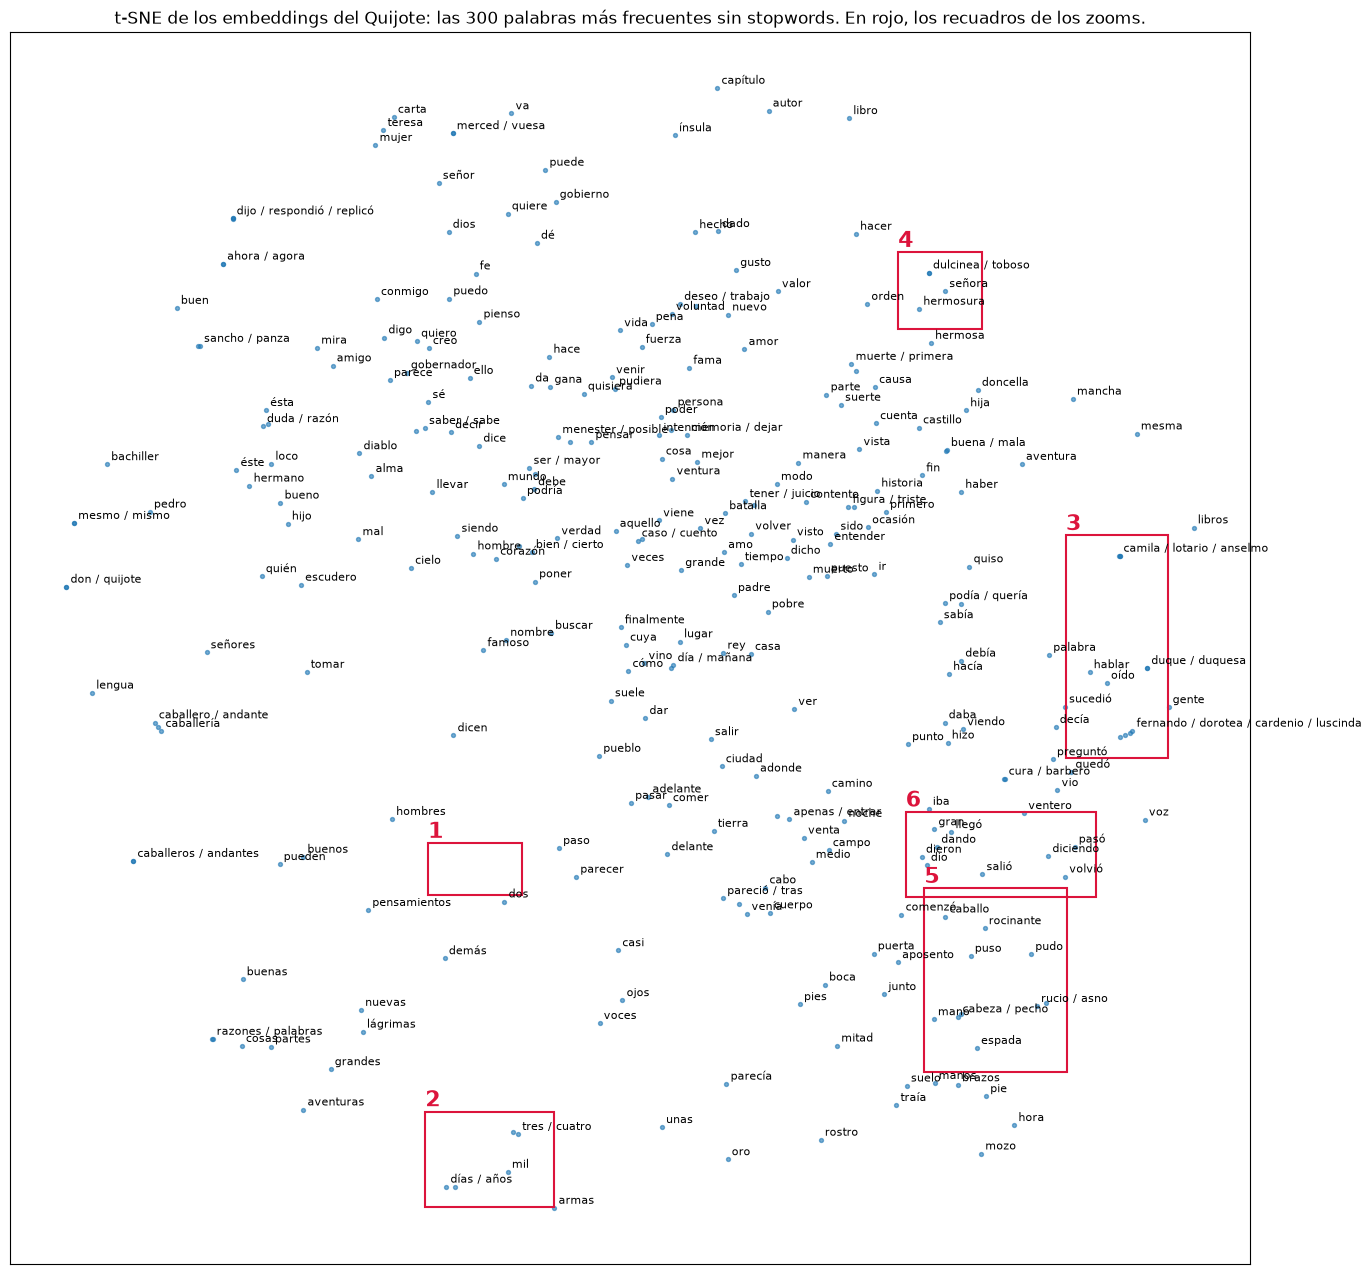

In [54]:
CLUSTERS = {  # nombre: palabras semilla que definen el recuadro del zoom
    'Las aventuras': ['molinos', 'viento', 'batanes', 'yangüeses', 'gigantes'],
    'Cantidades': ['tres', 'cuatro', 'seis', 'diez', 'cien', 'mil', 'días', 'años'],
    'Personajes por historia': ['fernando', 'dorotea', 'cardenio', 'luscinda', 'camila', 'lotario', 'anselmo',
                                'leonela', 'duque', 'duquesa'],
    'Dulcinea': ['dulcinea', 'toboso', 'señora', 'hermosura', 'princesa'],
    'Monturas': ['rocinante', 'caballo', 'jumento', 'cabestro', 'riendas', 'rucio', 'asno', 'mula', 'ancas', 'albarda'],
    'Verbos de la narración': ['llegó', 'salió', 'volvió', 'dio', 'pasó'],
}
posicion = {w: i for i, w in enumerate(labels)}


def recuadro(semillas, margen=1.5):
    """Rectángulo (x0, y0, x1, y1) que contiene a las semillas, con un margen."""
    p = vecs[[posicion[w] for w in semillas]]
    return (*(p.min(axis=0) - margen), *(p.max(axis=0) + margen))


def etiquetar(ax, indices, tol_x, tol_y, **kwargs):
    """Escribe las palabras. Las que quedan muy cerca comparten una etiqueta ("a / b") para que no se pisen;
    la tolerancia es mayor en x porque las etiquetas son horizontales."""
    grupos = []
    for i in indices:
        for g in grupos:
            dx, dy = np.abs(vecs[g[0]] - vecs[i])
            if dx < tol_x and dy < tol_y:
                g.append(i)
                break
        else:
            grupos.append([i])
    for g in grupos:
        ax.annotate(' / '.join(labels[g]), vecs[g[0]], xytext=(3, 3), textcoords='offset points', **kwargs)


fig, ax = plt.subplots(figsize=(16, 16))
ax.scatter(vecs[mapa, 0], vecs[mapa, 1], s=8, alpha=0.6)
etiquetar(ax, mapa, tol_x=1.2, tol_y=0.5, fontsize=8)
for n, semillas in enumerate(CLUSTERS.values(), start=1):
    x0, y0, x1, y1 = recuadro(semillas)
    ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor='crimson', linewidth=1.5))
    ax.text(x0, y1, str(n), color='crimson', fontsize=16, fontweight='bold', va='bottom')
ax.set_title(f't-SNE de los embeddings del Quijote: las {MAX_WORDS} palabras más frecuentes sin stopwords. '
             'En rojo, los recuadros de los zooms.')
ax.set_xticks([])
ax.set_yticks([])
plt.show()

**El mapa general**

- **Palabras pegadas.** Las etiquetas con `/` juntan palabras que quedan muy cerca, para que no se pisen. Varias están **exactamente en el mismo punto**, y son de dos tipos:
  - **colocaciones**, palabras que en el texto van siempre juntas: *don / quijote*, *sancho / panza*, *dulcinea / toboso*, *caballeros / andantes*, *duque / duquesa*, *merced / vuesa* («vuesa merced»);
  - **palabras intercambiables**: *dijo / respondió / replicó* (los verbos que cierran los diálogos: «—dijo Sancho», «—respondió don Quijote»), *razones / palabras*, las variantes *mesmo / mismo* y *ahora / agora*, y hasta los antónimos *buena / mala*.
- **Zonas.** El mapa está ordenado más por función que por tema. Arriba a la izquierda está el diálogo (*digo*, *quiero*, *creo*, *pienso*, *mira*, *amigo*, *señor*); arriba a la derecha, lo que el narrador dice del libro (*capítulo*, *autor*, *libro*); en el centro, los sustantivos abstractos (*vida*, *fama*, *voluntad*, *verdad*, *memoria*); a la derecha, los personajes secundarios y los verbos de la narración; abajo a la derecha, las cosas concretas (el cuerpo, las armas, las monturas), y abajo a la izquierda, los números.
- **Los recuadros** marcan los seis grupos que analizo con zoom. El 1 casi no tiene palabras en este mapa porque las suyas son menos frecuentes que las 300 graficadas: aparecen en el zoom.

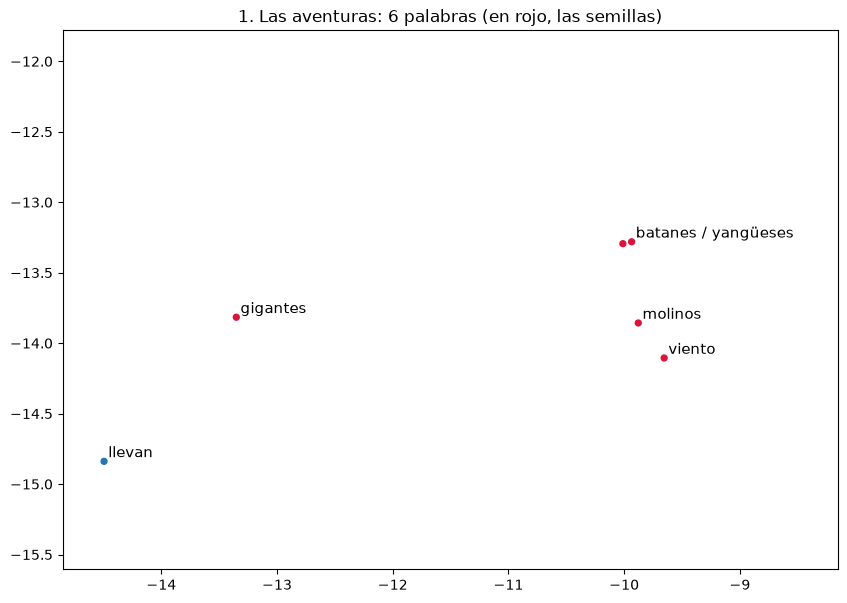

Apariciones: molinos 13, batanes 11, yangüeses 7, gigantes 31
Oraciones que nombran a dos o más (el fragmento entre la primera y la última):
   … allí se parecen no son gigantes sino molinos de viento y …
   … que sin duda alguna eran molinos de viento y no gigantes aquellos que iba …
   … los libros ha vuelto estos gigantes en molinos por quitarme la …
   … a la aventura de los molinos de viento que a vuestra merced le parecieron briareos y gigantes otros a la de los batanes éste a la descripción de los dos ejércitos que después parecieron ser dos manadas de carneros aquél encarece la del muerto que llevaban a enterrar a segovia uno dice que a todas se aventaja la de la libertad de los galeotes otro que ninguna iguala a la de los dos gigantes benitos con la …
   … tener dares y tomares con gigantes con endriagos y con vestiglos y a oír silbos rugidos bramidos y baladros y aun todo esto fuera flores de cantueso si no tuviéramos que entender con yangüeses y con moros …
   … pareció cuan

In [55]:
ZOOM_WORDS = 1500  # en los zooms entran las 1.500 palabras más frecuentes sin stopwords, más las semillas


def zoom(numero):
    """Grafica el recuadro del cluster `numero` (1 a 6) con todas sus palabras."""
    nombre, semillas = list(CLUSTERS.items())[numero - 1]
    x0, y0, x1, y1 = recuadro(semillas)
    candidatas = set(graficables[:ZOOM_WORDS]) | {posicion[w] for w in semillas}
    dentro = [i for i in sorted(candidatas) if x0 <= vecs[i, 0] <= x1 and y0 <= vecs[i, 1] <= y1]
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.scatter(vecs[dentro, 0], vecs[dentro, 1], s=18,
               c=['crimson' if labels[i] in semillas else 'tab:blue' for i in dentro])
    etiquetar(ax, dentro, tol_x=0.07 * (x1 - x0), tol_y=0.025 * (y1 - y0), fontsize=11)
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_title(f'{numero}. {nombre}: {len(dentro)} palabras (en rojo, las semillas)')
    plt.show()


zoom(1)

AVENTURAS = ['molinos', 'batanes', 'yangüeses', 'gigantes']
print('Apariciones:', ', '.join(f"{w} {modelo.wv.get_vecattr(w, 'count')}" for w in AVENTURAS))
print('Oraciones que nombran a dos o más (el fragmento entre la primera y la última):')
for t in oraciones_tokens:
    posiciones = [i for i, w in enumerate(t) if w in AVENTURAS]
    if len({t[i] for i in posiciones}) >= 2:
        print('   …', ' '.join(t[max(0, posiciones[0] - 5):posiciones[-1] + 4]), '…')

**1. Las aventuras.** *molinos*, *viento*, *batanes*, *yangüeses* y *gigantes* quedan juntas y lejos del resto. No son cosas parecidas: hay máquinas (los molinos de viento, que don Quijote toma por gigantes, y los mazos de batán, cuyo ruido lo asusta toda una noche) y personas (los arrieros de Yanguas que apalean a Rocinante). Se agrupan porque **aparecen en las mismas oraciones**: en el episodio de los molinos («no son gigantes sino molinos de viento») y, sobre todo, cuando los personajes **recuerdan y enumeran las aventuras** de la primera parte («unos se atienen a la aventura de los molinos de viento… otros a la de los batanes»), además de los títulos de los capítulos. Son palabras poco frecuentes (de 7 a 31 apariciones), así que esas pocas oraciones definen su vector, y *molinos* casi siempre va en «molinos de viento», por eso *viento* cae al lado. Dentro del libro tiene sentido, porque son "las aventuras", pero es una relación del texto y no del significado: **overfitting a unas pocas frases**, como *yellow submarine* en las canciones.

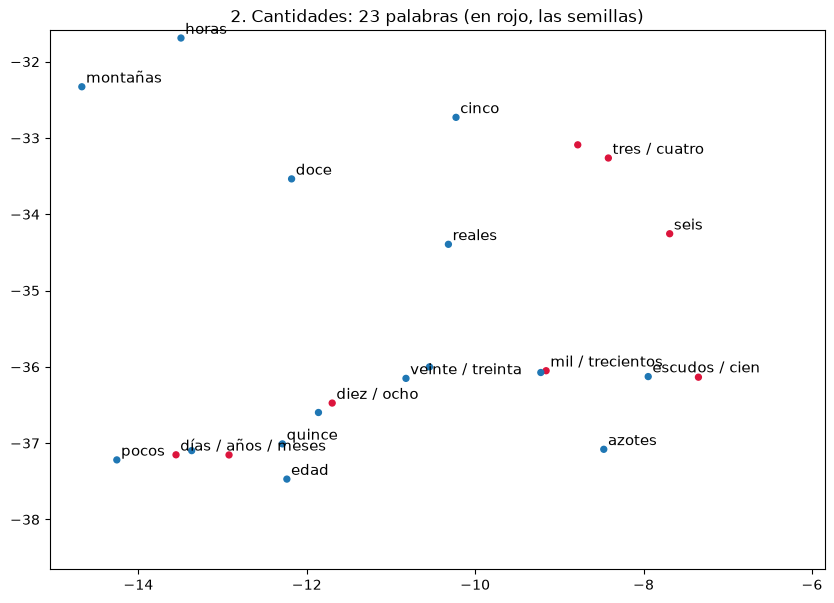

In [56]:
zoom(2)

**2. Cantidades.** Los números (*tres*, *cuatro*, *cinco*, *seis*, *ocho*, *diez*, *doce*, *veinte*, *treinta*, *cien*, *mil*, *trecientos*, con la ortografía de la época) junto con las unidades de tiempo (*días*, *años*, *horas*, *meses*, *edad*) y con lo que se cuenta en el libro: *azotes* (los 3.300 que Sancho se tiene que dar para desencantar a Dulcinea), *escudos* y *reales*. La única que no encaja es *montañas*. Es el grupo con más sentido: los números son intercambiables en la oración (*tres días*, *cuatro días*, *cien escudos*), así que tienen contextos casi iguales. Es el mismo cluster de números que apareció con los Beatles (*four*, *five*, *six*).

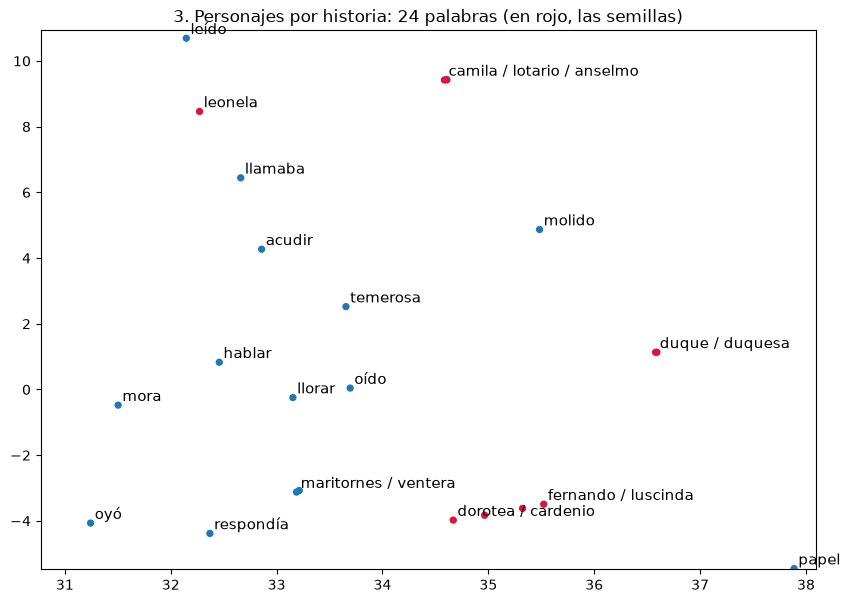

In [57]:
zoom(3)

**3. Personajes por historia.** Los personajes secundarios se agrupan según **la historia en la que aparecen**: *camila*, *lotario*, *anselmo* y *leonela* son la novela del *Curioso impertinente*, que se lee en voz alta en la venta; *fernando*, *dorotea*, *cardenio* y *luscinda* son los dos pares de enamorados de Sierra Morena, con *maritornes* y la *ventera* cerca; *duque* y *duquesa* son de la segunda parte. Cada historia ocupa capítulos seguidos donde esos nombres aparecen juntos y casi no salen en el resto del libro. El modelo **recupera la estructura del libro**, pero es pura co-ocurrencia: no dice nada de los personajes en sí. Entre los grupos quedan verbos de habla y de lectura (*oyó*, *llamaba*, *hablar*, *leído*): son las acciones de esos personajes.

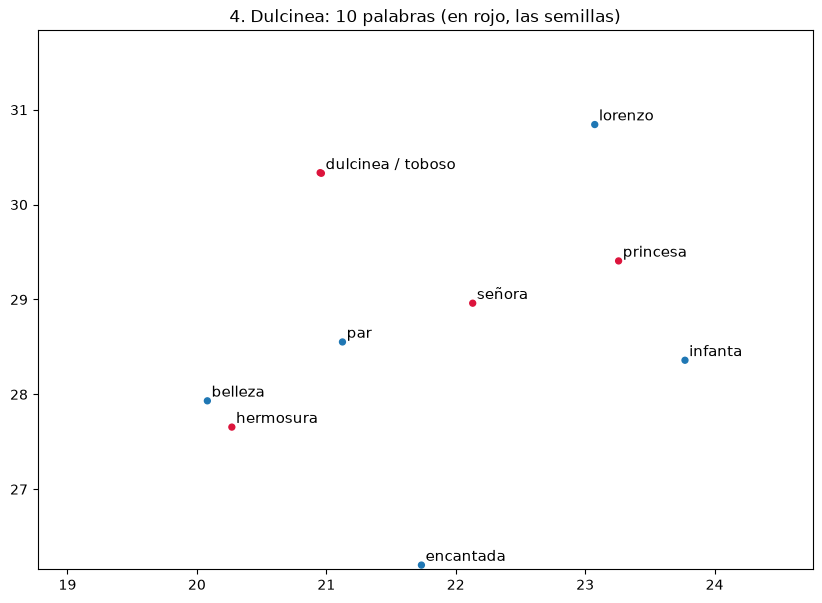

In [58]:
zoom(4)

**4. Dulcinea.** *dulcinea* y *toboso* caen en el mismo punto, porque casi siempre van juntas («Dulcinea del Toboso»). Alrededor están *señora*, *hermosura*, *belleza*, *princesa*, *infanta*, *par* («la sin par Dulcinea»), *encantada* (su encantamiento en la segunda parte) y *lorenzo* (Aldonza Lorenzo, su nombre real). Es el vocabulario con que don Quijote habla de su dama, idealizada como en los libros de caballerías. **Tiene sentido**: el modelo captó el registro caballeresco del amor cortés, aunque Dulcinea no aparece nunca en persona.

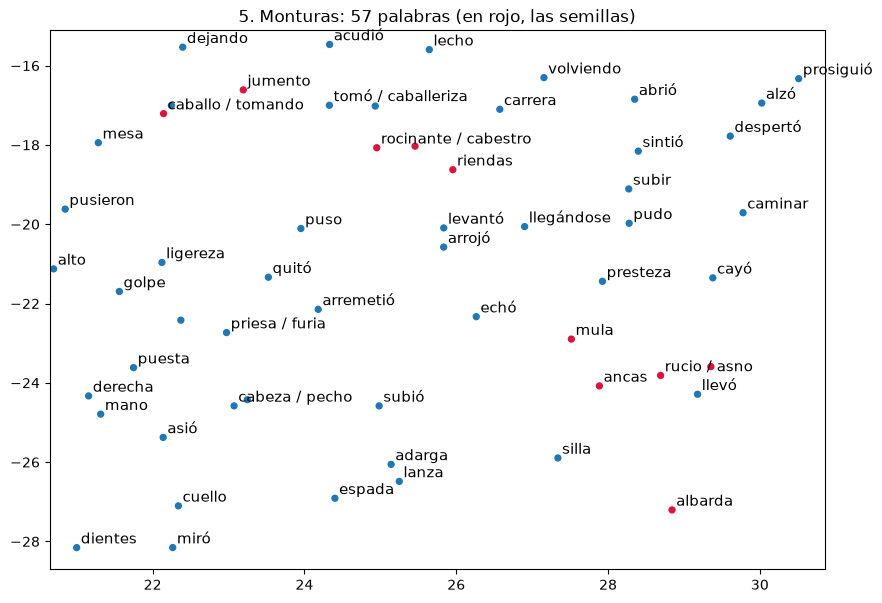

In [59]:
zoom(5)

**5. Monturas.** Hay dos subgrupos: *rocinante*, *caballo*, *jumento*, *cabestro* y *riendas* por un lado, y *rucio*, *asno*, *mula*, *ancas*, *silla* y *albarda* por el otro, es decir, los animales con sus aparejos. Pero el recuadro está lleno de **partes del cuerpo** (*mano*, *cabeza*, *pecho*, *cuello*, *dientes*), **armas** (*espada*, *lanza*) y **verbos de movimiento** (*subir*, *alzó*, *echó*, *arremetió*, *cayó*): es la zona de las escenas de acción física. Con skip-gram y ventana 5, *rocinante* queda cerca de lo que aparece en sus oraciones («subió sobre Rocinante», «puso mano a la espada»), no solo de otros animales. Como tema tiene sentido, pero **no es un grupo de sinónimos**: muestra que la proximidad en Word2Vec mezcla "parecido" con "aparece en la misma escena".

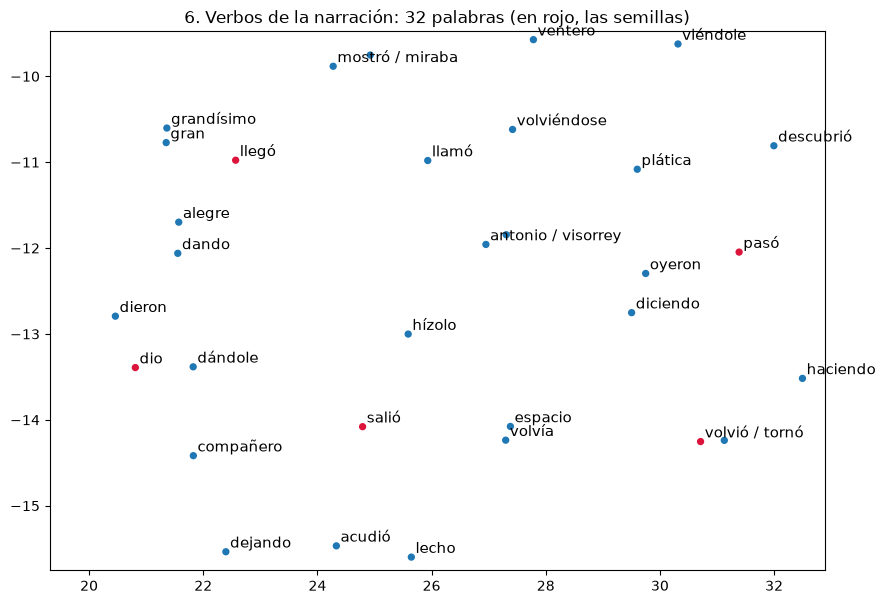

In [60]:
zoom(6)

**6. Verbos de la narración.** *dio*, *llegó*, *volvió*, *salió*, *pasó*, *dieron*, *mostró*, *tornó* (pretérito) y *diciendo*, *dando*, *haciendo*, *dejando* (gerundio): las formas con que el narrador cuenta lo que pasa. Es un cluster **gramatical**, no de significado: *dio* y *salió* no significan lo mismo, pero ocupan el mismo lugar en la oración («llegó el cura», «salió el ventero»). Cerca quedan personajes de la segunda parte que son sujetos de esas oraciones (*ventero*, *antonio*, *visorrey*). Muestra que los embeddings también capturan la sintaxis, no solo el tema.

El mismo mapa en Plotly, como en la plantilla, para explorarlo con zoom en Colab (GitHub no muestra los gráficos de Plotly):

In [61]:
fig = px.scatter(x=vecs[mapa, 0], y=vecs[mapa, 1], text=labels[mapa])
fig.update_traces(marker_size=4, textposition='top center')
fig.show(renderer="colab")  # esto para plotly en colab

## 7. Conclusiones

1. **Con un solo libro, Word2Vec aprende relaciones con sentido sin ningún diccionario.** Junta sinónimos (*miedo* → *espanto*, *temor*; *venta* → *mesón*), descubre que las formas antiguas son las mismas palabras que las modernas (*mesmo* → *mismo*, *agora* → *ahora*), arma categorías (números, monturas, el vocabulario de la dama y el de la caballería) y resuelve analogías propias del libro (*quijote : mancha :: dulcinea : toboso*, *rey : reino :: gobernador : ínsula*, *sancho : teresa :: duque : duquesa*). Es la hipótesis distributiva funcionando: todo sale de los contextos.
2. **Lo que más pesa entre los hiperparámetros** es entrenar suficientes épocas (con las 5 de Gensim los vectores casi no se alejan del azar), usar skip-gram en vez de CBOW con un corpus chico y elegir una ventana acorde al largo de las oraciones: 2 es poco para oraciones de 28 tokens, y 10 cambia el tipo de similitud ("aparecen en la misma escena" en vez de "se pueden intercambiar"). `negative` entre 5 y 20 y `vector_size` entre 50 y 100 dan casi lo mismo; 300 dimensiones son demasiadas para este corpus. Un `min_count` bajo llena los vecinos de palabras raras. Medir cuánto cambian los resultados con la semilla fue clave para no sobreinterpretar diferencias chicas.
3. **Límites:**
   - **Tamaño del corpus y overfitting:** muchas relaciones salen de pocas frases que se repiten (*yelmo de Mambrino*, *molinos de viento*, *Dulcinea del Toboso*, *los doce pares de Francia*): el modelo aprende la frase, no el concepto. Es el mismo problema de *yellow submarine*, más acotado.
   - **Frecuencia:** las palabras raras tienen vectores poco confiables, y una palabra abstracta que se usa en contextos muy variados, como *amor*, queda con vecinos sin sentido aunque sea frecuente.
   - **Polisemia:** *real* y *lugar* tienen un solo vector que mezcla sus sentidos. *escudo* y *escudos* se separan solo porque, por casualidad, el singular es casi siempre el arma y el plural, la moneda.
   - **Español antiguo:** las variantes (*mesmo*/*mismo*, *fermosa*/*hermosa*) reparten las apariciones de una palabra entre dos vectores, cada uno con menos datos.
   - **Lo menos similar no es lo opuesto:** los antónimos quedan cerca porque comparten contextos, y las palabras "menos similares" son simplemente palabras sin relación.
   - **Analogías generales:** *hombre : mujer :: rey : reina* falla. En el libro hay pocos ejemplos de esas relaciones, *reina* aparece poco y *mujer* se usa muchas veces como "esposa".
4. **Qué mejoraría:**
   - **Más texto** del mismo autor y época (las *Novelas ejemplares*, el *Persiles*) o libros de caballerías, para tener más contextos por palabra.
   - **Juntar las colocaciones** en un solo token (*don_quijote*, *sancho_panza*, *dulcinea_del_toboso*) con `gensim.models.Phrases`, para que el nombre completo tenga un vector propio.
   - **Normalizar la ortografía antigua** (*mesmo* → *mismo*, *agora* → *ahora*) o lematizar, para juntar los datos de cada palabra.
   - **fastText**, que arma los vectores con n-gramas de caracteres: las variantes (*fermosura*/*hermosura*) y las palabras raras compartirían información.